EXPLORATORY DATA ANALYSIS

In [1]:
# importing the basic libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import os
import sys
sys.path.append(os.path.abspath(".."))

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

In [2]:
# load the data
DATA_PATH: Path = Path("../data/raw")

column_names = (
    ["engine_id", "cycle"] + [f"setting_{i}" for i in range(1, 4)] + [f"sensor_{i}" for i in range(1, 22)]
)

train_data: pd.DataFrame = pd.read_csv(
    DATA_PATH / "train_FD004.txt",
    sep = r"\s+",
    header = None,
    names = column_names
)

test_data: pd.DataFrame = pd.read_csv(
    DATA_PATH / "test_FD004.txt",
    sep = r"\s+",
    header = None,
    names = column_names
)

RUL_data: pd.DataFrame = pd.read_csv(
    DATA_PATH / "RUL_FD004.txt",
    sep = r"\s+",
    header = None,
    names = ["RUL"]
)

In [3]:
print(f"training-data shape: {train_data.shape}")
print(f"testing-data shape: {test_data.shape}")
print(f"RUL-data shape: {RUL_data.shape}")

training-data shape: (61249, 26)
testing-data shape: (41214, 26)
RUL-data shape: (248, 1)


In [4]:
train_data.head()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,42.0049,0.8400,100.0,445.00,549.68,1343.43,1112.93,3.91,5.70,137.36,2211.86,8311.32,1.01,41.69,129.78,2387.99,8074.83,9.3335,0.02,330,2212,100.00,10.62,6.3670
1,1,2,20.0020,0.7002,100.0,491.19,606.07,1477.61,1237.50,9.35,13.61,332.10,2323.66,8713.60,1.07,43.94,312.59,2387.73,8046.13,9.1913,0.02,361,2324,100.00,24.37,14.6552
2,1,3,42.0038,0.8409,100.0,445.00,548.95,1343.12,1117.05,3.91,5.69,138.18,2211.92,8306.69,1.01,41.66,129.62,2387.97,8066.62,9.4007,0.02,329,2212,100.00,10.48,6.4213
3,1,4,42.0000,0.8400,100.0,445.00,548.70,1341.24,1118.03,3.91,5.70,137.98,2211.88,8312.35,1.02,41.68,129.80,2388.02,8076.05,9.3369,0.02,328,2212,100.00,10.54,6.4176
4,1,5,25.0063,0.6207,60.0,462.54,536.10,1255.23,1033.59,7.05,9.00,174.82,1915.22,7994.94,0.93,36.48,164.11,2028.08,7865.80,10.8366,0.02,305,1915,84.93,14.03,8.6754


In [5]:
test_data.head()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,20.0072,0.7000,100.0,491.19,606.67,1481.04,1227.81,9.35,13.60,332.52,2323.67,8704.98,1.07,43.83,313.03,2387.78,8048.98,9.2229,0.02,362,2324,100.00,24.31,14.7007
1,1,2,24.9984,0.6200,60.0,462.54,536.22,1256.17,1031.48,7.05,9.00,174.46,1915.21,7999.94,0.93,36.11,163.61,2028.09,7863.46,10.8632,0.02,306,1915,84.93,14.36,8.5748
2,1,3,42.0000,0.8420,100.0,445.00,549.23,1340.13,1105.88,3.91,5.69,137.34,2211.93,8305.38,1.01,41.52,129.98,2387.95,8071.13,9.3960,0.02,328,2212,100.00,10.39,6.4365
3,1,4,42.0035,0.8402,100.0,445.00,549.19,1339.70,1107.26,3.91,5.69,137.23,2211.89,8301.00,1.01,41.73,129.48,2387.90,8078.89,9.3594,0.02,328,2212,100.00,10.56,6.2367
4,1,5,35.0079,0.8400,100.0,449.44,555.10,1353.04,1117.80,5.48,7.97,192.94,2222.71,8331.05,1.02,41.32,181.82,2387.87,8057.83,9.3030,0.02,333,2223,100.00,14.85,8.9326


TARGET VARIABLE CREATION FOR TRAINING DATA

In [6]:
train_data.describe()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
count,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000
mean,124.325181,134.311417,23.999823,0.571347,94.031576,472.882435,579.420056,1417.896600,1201.915359,8.031626,11.589457,283.328633,2228.686034,8524.673301,1.096445,42.874529,266.735665,2334.427590,8067.811812,9.285604,0.023252,347.760029,2228.613283,97.751396,20.864333,12.518995
std,71.995350,89.783389,14.780722,0.310703,14.251954,26.436832,37.342647,106.167598,119.327591,3.622872,5.444017,146.880210,145.348243,336.927547,0.127681,3.243492,138.479109,128.197859,85.670543,0.750374,0.004685,27.808283,145.472491,5.369424,9.936396,5.962697
min,1.000000,1.000000,0.000000,0.000000,60.000000,445.000000,535.480000,1242.670000,1024.420000,3.910000,5.670000,136.170000,1914.720000,7984.510000,0.930000,36.040000,128.310000,2027.570000,7845.780000,8.175700,0.020000,302.000000,1915.000000,84.930000,10.160000,6.084300
25%,60.000000,62.000000,10.004600,0.250700,100.000000,445.000000,549.330000,1350.550000,1119.490000,3.910000,5.720000,142.920000,2211.950000,8320.590000,1.020000,41.760000,134.520000,2387.910000,8062.630000,8.648000,0.020000,330.000000,2212.000000,100.000000,10.940000,6.566100
50%,126.000000,123.000000,25.001400,0.700000,100.000000,462.540000,555.740000,1367.680000,1136.920000,7.050000,9.030000,194.960000,2223.070000,8362.760000,1.030000,42.330000,183.450000,2388.060000,8083.810000,9.255600,0.020000,334.000000,2223.000000,100.000000,14.930000,8.960100
75%,185.000000,191.000000,41.998100,0.840000,100.000000,491.190000,607.070000,1497.420000,1302.620000,10.520000,15.480000,394.280000,2323.930000,8777.250000,1.260000,45.220000,371.400000,2388.170000,8128.350000,9.365800,0.030000,368.000000,2324.000000,100.000000,28.560000,17.135500
max,249.000000,543.000000,42.008000,0.842000,100.000000,518.670000,644.420000,1613.000000,1440.770000,14.620000,21.610000,570.810000,2388.640000,9196.810000,1.320000,48.360000,537.490000,2390.490000,8261.650000,11.066300,0.030000,399.000000,2388.000000,100.000000,39.890000,23.885200


FORMULATION OF RUL : MAX(CYCLE) - CURRENT(CYCLE) FOR AN ENGINE

In [7]:
train_data["RUL"] = train_data.groupby(by = "engine_id")["cycle"].transform("max") - train_data["cycle"]

In [8]:
train_data[train_data["engine_id"] == 1].tail(15)

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
306,1,307,42.0038,0.8400,100.0,445.00,549.93,1363.45,1137.96,3.91,5.69,141.34,2212.37,8363.26,1.04,42.50,133.13,2388.51,8125.15,9.1589,0.02,332,2212,100.0,10.81,6.4590,14
307,1,308,42.0074,0.8412,100.0,445.00,549.88,1357.00,1132.47,3.91,5.69,141.26,2212.46,8366.82,1.04,42.42,133.22,2388.48,8126.42,9.1432,0.02,332,2212,100.0,10.66,6.4843,13
308,1,309,20.0038,0.7015,100.0,491.19,607.38,1495.68,1259.69,9.35,13.61,340.88,2324.52,8765.05,1.09,44.85,321.49,2388.64,8094.77,8.9928,0.03,367,2324,100.0,24.91,14.9363,12
309,1,310,42.0014,0.8400,100.0,445.00,549.86,1357.47,1141.17,3.91,5.70,141.65,2212.35,8368.92,1.04,42.43,133.49,2388.49,8130.04,9.1095,0.02,332,2212,100.0,10.71,6.5409,11
310,1,311,42.0044,0.8401,100.0,445.00,549.86,1364.90,1141.20,3.91,5.69,141.82,2212.41,8369.27,1.04,42.40,133.26,2388.50,8125.58,9.0937,0.02,332,2212,100.0,10.79,6.4548,10
311,1,312,35.0045,0.8401,100.0,449.44,556.27,1373.18,1144.22,5.48,7.97,198.81,2223.64,8399.85,1.04,42.29,186.93,2388.71,8112.69,9.1149,0.02,336,2223,100.0,15.19,9.0905,9
312,1,313,0.0001,0.0000,100.0,518.67,643.17,1603.28,1422.10,14.62,21.58,566.02,2388.50,9105.29,1.31,47.88,533.56,2388.43,8177.62,8.2634,0.03,397,2388,100.0,39.45,23.8649,8
313,1,314,35.0069,0.8400,100.0,449.44,556.18,1376.49,1138.61,5.48,7.97,199.23,2223.63,8396.37,1.04,42.24,187.38,2388.78,8114.56,9.1487,0.02,337,2223,100.0,15.13,9.2299,7
314,1,315,0.0019,0.0000,100.0,518.67,643.50,1598.22,1422.53,14.62,21.59,567.07,2388.49,9114.84,1.31,47.98,534.25,2388.43,8182.88,8.2503,0.03,395,2388,100.0,39.54,23.7277,6
315,1,316,42.0050,0.8402,100.0,445.00,549.59,1366.82,1136.94,3.91,5.70,142.47,2212.45,8373.77,1.05,42.73,133.41,2388.51,8132.30,9.1495,0.02,335,2212,100.0,10.81,6.5671,5


In [9]:
# missing values check
train_data.isnull().sum()

engine_id    0
cycle        0
setting_1    0
setting_2    0
setting_3    0
sensor_1     0
sensor_2     0
sensor_3     0
sensor_4     0
sensor_5     0
sensor_6     0
sensor_7     0
sensor_8     0
sensor_9     0
sensor_10    0
sensor_11    0
sensor_12    0
sensor_13    0
sensor_14    0
sensor_15    0
sensor_16    0
sensor_17    0
sensor_18    0
sensor_19    0
sensor_20    0
sensor_21    0
RUL          0
dtype: int64

In [10]:
# duplicate rows
train_data.duplicated().sum()

np.int64(0)

In [11]:
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 61249 entries, 0 to 61248
Data columns (total 27 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   engine_id  61249 non-null  int64  
 1   cycle      61249 non-null  int64  
 2   setting_1  61249 non-null  float64
 3   setting_2  61249 non-null  float64
 4   setting_3  61249 non-null  float64
 5   sensor_1   61249 non-null  float64
 6   sensor_2   61249 non-null  float64
 7   sensor_3   61249 non-null  float64
 8   sensor_4   61249 non-null  float64
 9   sensor_5   61249 non-null  float64
 10  sensor_6   61249 non-null  float64
 11  sensor_7   61249 non-null  float64
 12  sensor_8   61249 non-null  float64
 13  sensor_9   61249 non-null  float64
 14  sensor_10  61249 non-null  float64
 15  sensor_11  61249 non-null  float64
 16  sensor_12  61249 non-null  float64
 17  sensor_13  61249 non-null  float64
 18  sensor_14  61249 non-null  float64
 19  sensor_15  61249 non-null  float64
 20  sensor_16  61249 

In [12]:
train_data.describe()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
count,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000,61249.000000
mean,124.325181,134.311417,23.999823,0.571347,94.031576,472.882435,579.420056,1417.896600,1201.915359,8.031626,11.589457,283.328633,2228.686034,8524.673301,1.096445,42.874529,266.735665,2334.427590,8067.811812,9.285604,0.023252,347.760029,2228.613283,97.751396,20.864333,12.518995,133.311417
std,71.995350,89.783389,14.780722,0.310703,14.251954,26.436832,37.342647,106.167598,119.327591,3.622872,5.444017,146.880210,145.348243,336.927547,0.127681,3.243492,138.479109,128.197859,85.670543,0.750374,0.004685,27.808283,145.472491,5.369424,9.936396,5.962697,89.783389
min,1.000000,1.000000,0.000000,0.000000,60.000000,445.000000,535.480000,1242.670000,1024.420000,3.910000,5.670000,136.170000,1914.720000,7984.510000,0.930000,36.040000,128.310000,2027.570000,7845.780000,8.175700,0.020000,302.000000,1915.000000,84.930000,10.160000,6.084300,0.000000
25%,60.000000,62.000000,10.004600,0.250700,100.000000,445.000000,549.330000,1350.550000,1119.490000,3.910000,5.720000,142.920000,2211.950000,8320.590000,1.020000,41.760000,134.520000,2387.910000,8062.630000,8.648000,0.020000,330.000000,2212.000000,100.000000,10.940000,6.566100,61.000000
50%,126.000000,123.000000,25.001400,0.700000,100.000000,462.540000,555.740000,1367.680000,1136.920000,7.050000,9.030000,194.960000,2223.070000,8362.760000,1.030000,42.330000,183.450000,2388.060000,8083.810000,9.255600,0.020000,334.000000,2223.000000,100.000000,14.930000,8.960100,122.000000
75%,185.000000,191.000000,41.998100,0.840000,100.000000,491.190000,607.070000,1497.420000,1302.620000,10.520000,15.480000,394.280000,2323.930000,8777.250000,1.260000,45.220000,371.400000,2388.170000,8128.350000,9.365800,0.030000,368.000000,2324.000000,100.000000,28.560000,17.135500,190.000000
max,249.000000,543.000000,42.008000,0.842000,100.000000,518.670000,644.420000,1613.000000,1440.770000,14.620000,21.610000,570.810000,2388.640000,9196.810000,1.320000,48.360000,537.490000,2390.490000,8261.650000,11.066300,0.030000,399.000000,2388.000000,100.000000,39.890000,23.885200,542.000000


VISUALIZE THE DISTRIBUTION OF EACH SENSOR READINGS

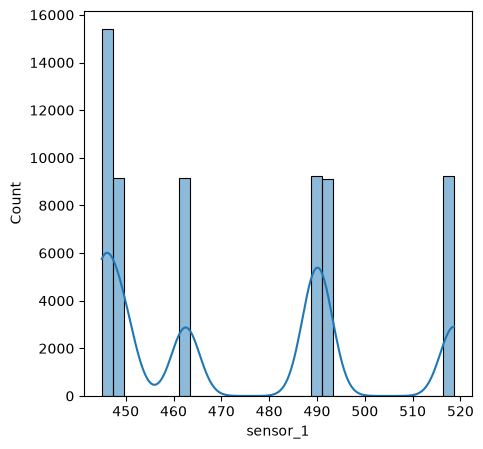

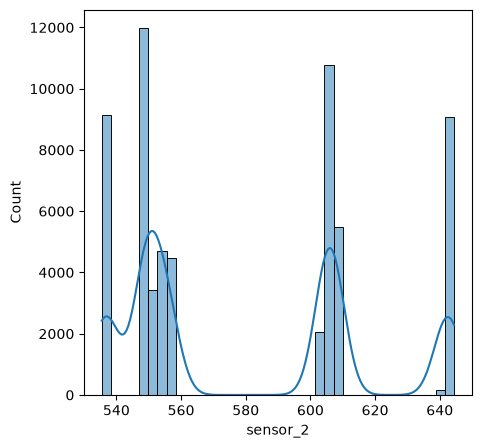

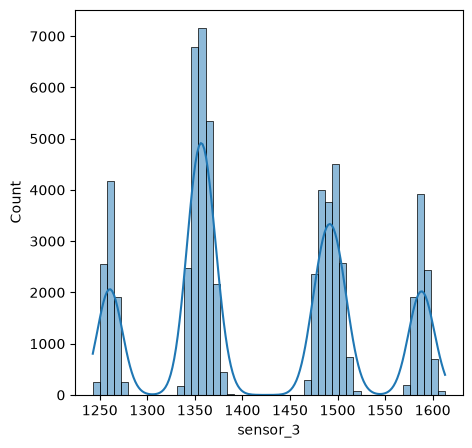

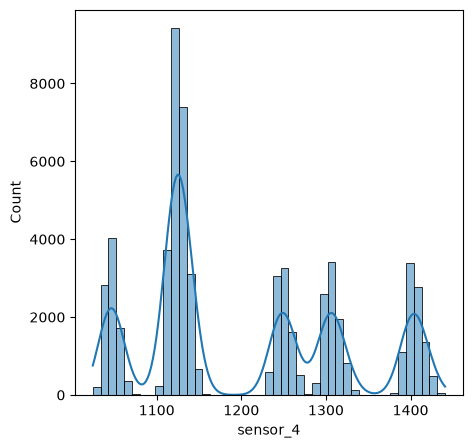

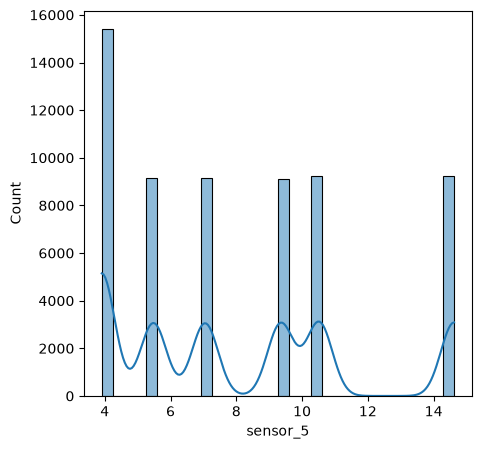

...

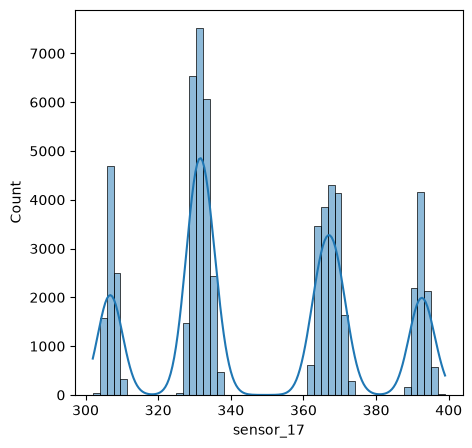

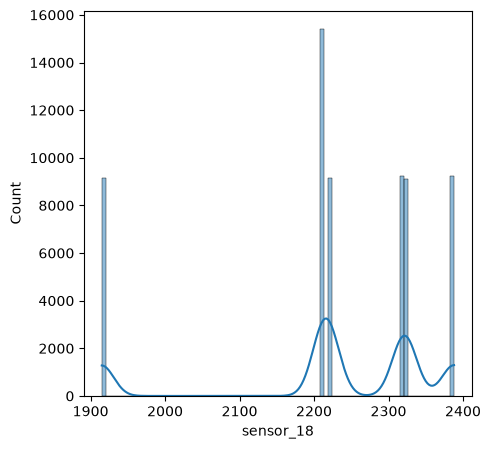

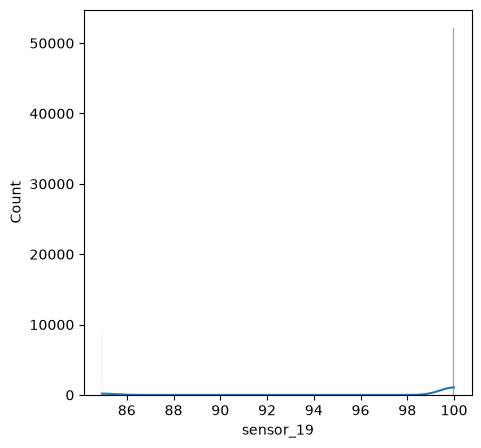

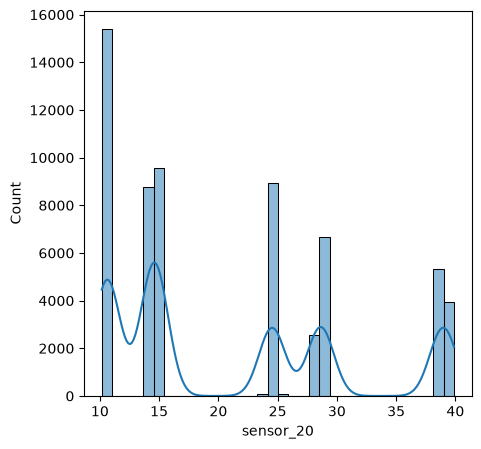

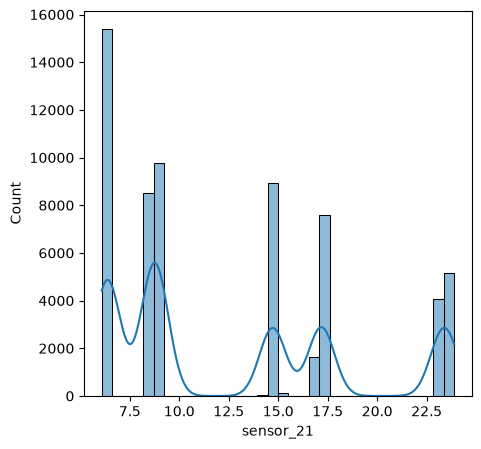

In [13]:
for i in range(1, 22):
    plt.figure(figsize = (5, 5))
    sns.histplot(data = train_data, x = f"sensor_{i}", kde = True)

VISUALIZING THE SENSOR READINGS FOR A PARTICULAR ENGINE(31)

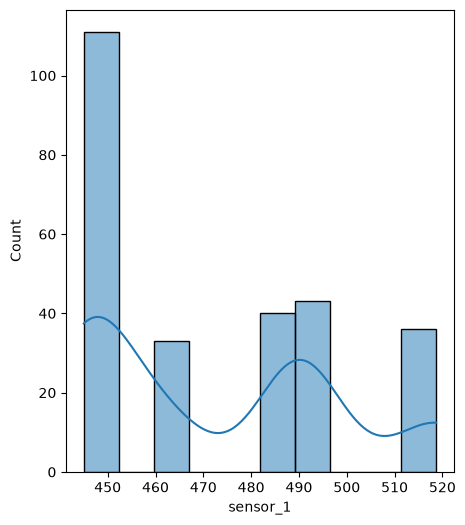

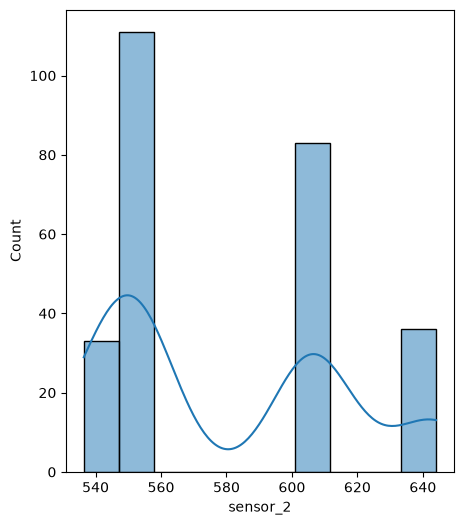

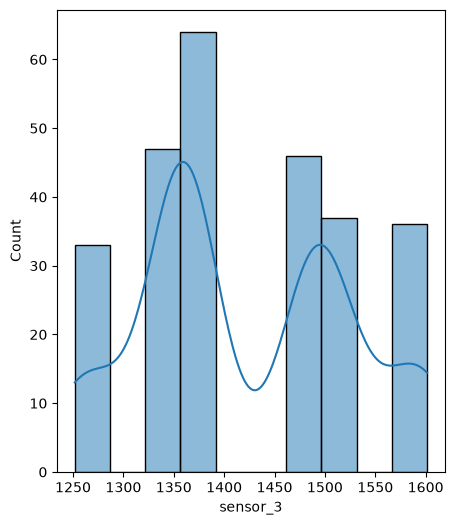

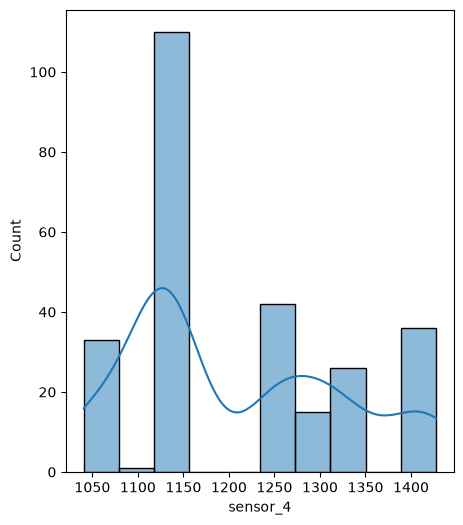

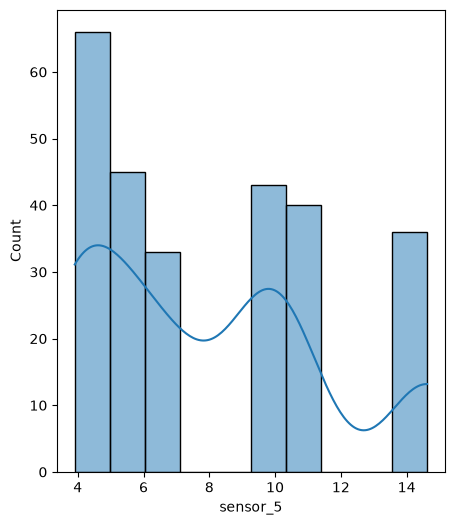

...

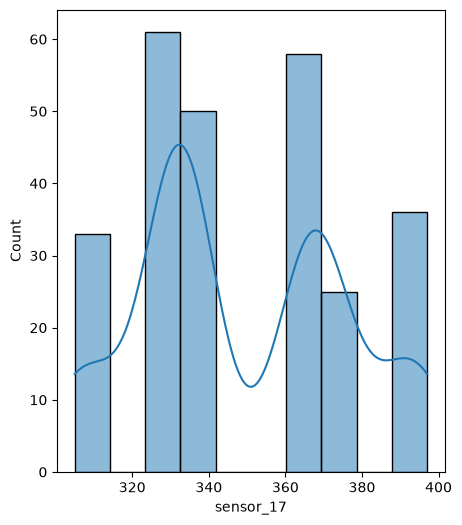

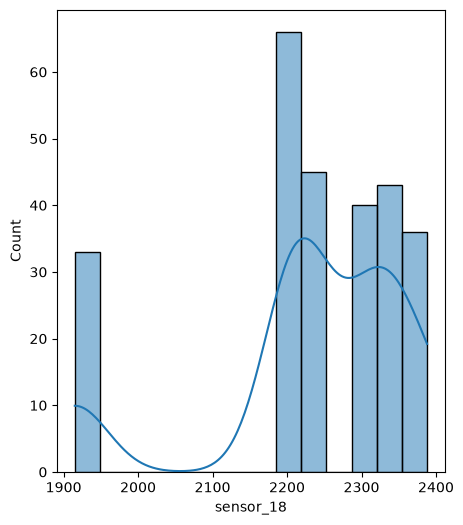

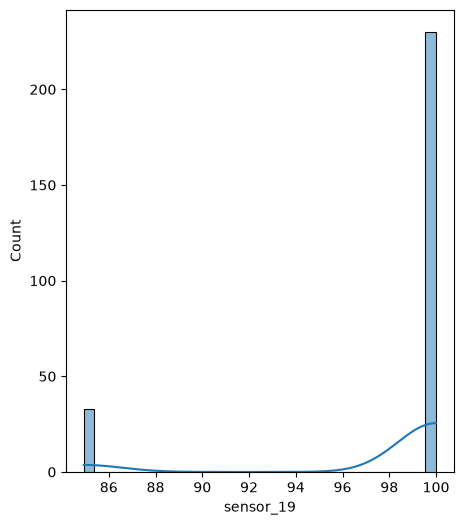

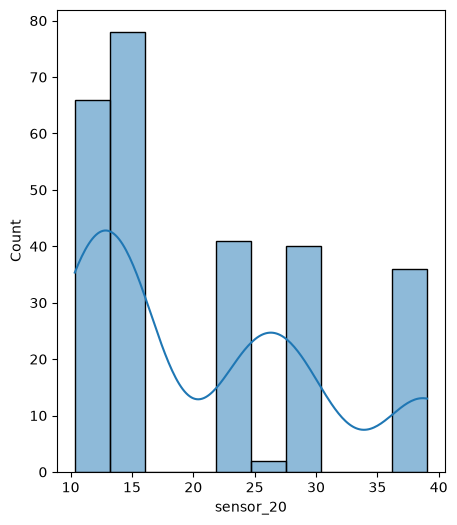

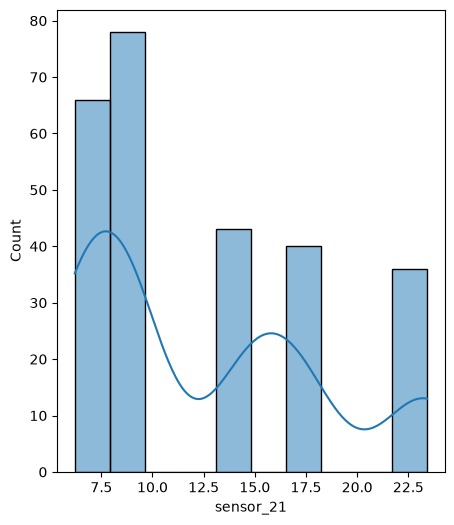

In [14]:
engine31_data: pd.DataFrame = train_data[train_data["engine_id"] == 31]
for i in range(1, 22):
    plt.figure(figsize = (5, 6))
    sns.histplot(data = engine31_data, x = f"sensor_{i}", kde = True)

CHECKING FOR LINEAR RELATIONSHIPS B/W SENSOR READINGS OF ENGINE 31 WITH THE RUL

<Axes: >

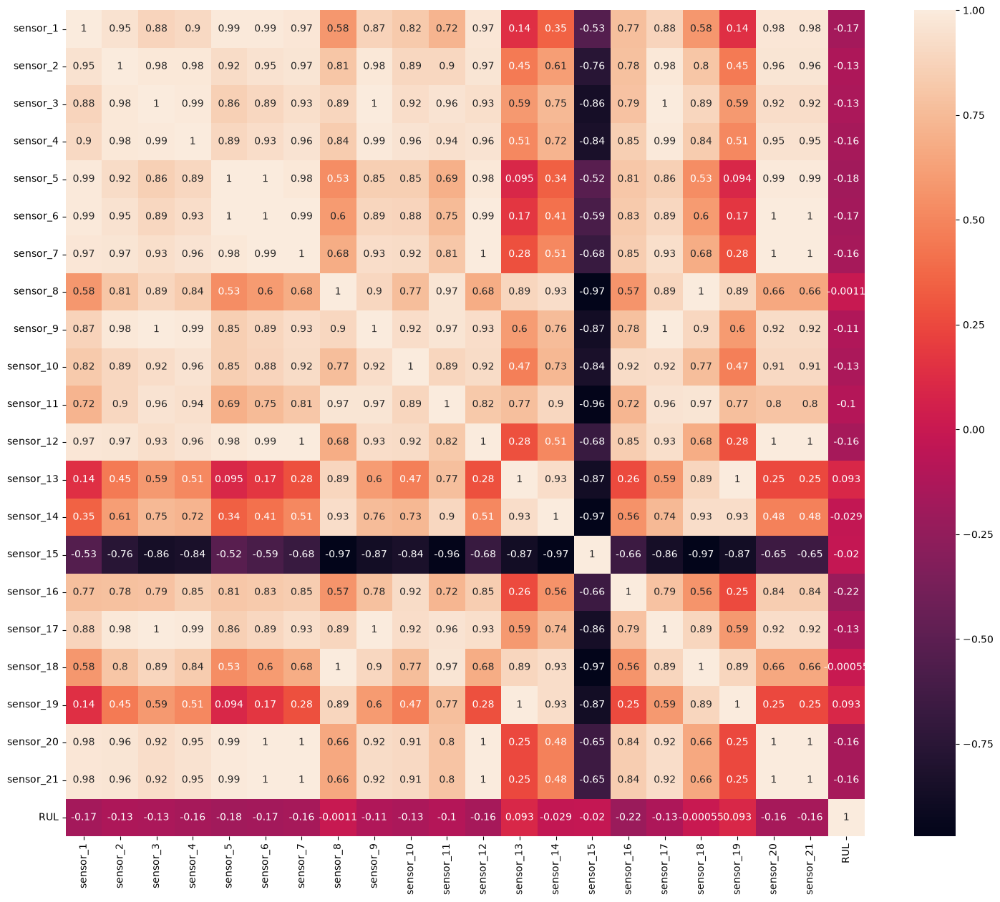

In [15]:
corr_cols = [f"sensor_{i}" for i in range(1, 22)] + ["RUL"]
plt.figure(figsize = (18, 15))
sns.heatmap(data = engine31_data[corr_cols].corr(), annot = True)

HEATMAP FOR THE ENTIRE TRAINING DATASET

<Axes: >

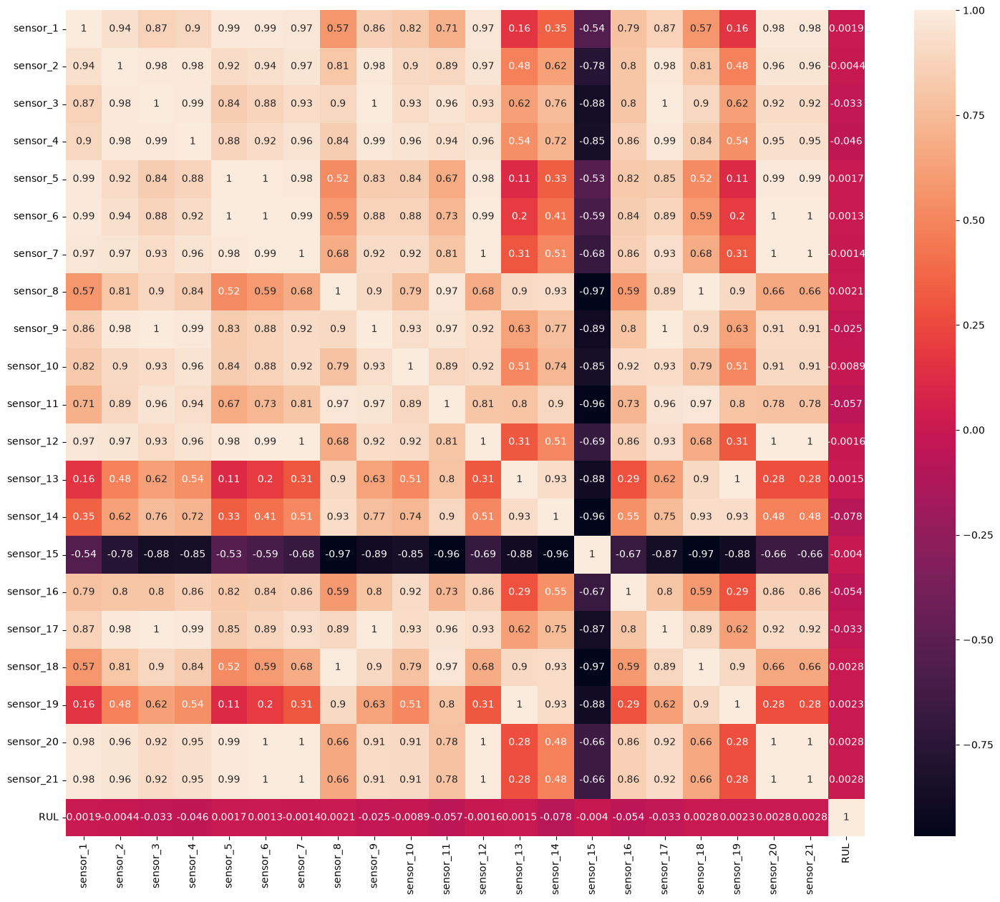

In [16]:
corr_cols = [f"sensor_{i}" for i in range(1, 22)] + ["RUL"]
plt.figure(figsize = (18, 15))
sns.heatmap(data = train_data[corr_cols].corr(), annot = True)

In [17]:
engine31_data.head()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
7563,31,1,35.0077,0.8400,100.0,449.44,555.76,1366.01,1134.32,5.48,8.00,194.52,2222.90,8345.41,1.02,41.68,183.51,2388.02,8065.24,9.3149,0.02,332,2223,100.0,14.82,8.9180,262
7564,31,2,42.0032,0.8412,100.0,445.00,549.42,1351.74,1119.00,3.91,5.71,139.07,2211.85,8320.65,1.02,42.01,131.13,2387.99,8085.27,9.3271,0.02,330,2212,100.0,10.76,6.4224,261
7565,31,3,42.0017,0.8400,100.0,445.00,549.98,1354.41,1125.57,3.91,5.71,138.34,2211.78,8313.35,1.02,41.87,130.96,2387.85,8079.11,9.3629,0.02,331,2212,100.0,10.73,6.3930,260
7566,31,4,0.0018,0.0012,100.0,518.67,642.64,1582.64,1401.10,14.62,21.61,553.95,2388.08,9058.47,1.30,47.45,521.73,2388.07,8136.93,8.3996,0.03,392,2388,100.0,38.70,23.3848,259
7567,31,5,42.0074,0.8410,100.0,445.00,549.33,1353.18,1125.67,3.91,5.72,138.28,2211.81,8313.17,1.02,42.07,130.26,2387.86,8079.26,9.3823,0.02,330,2212,100.0,10.67,6.4301,258


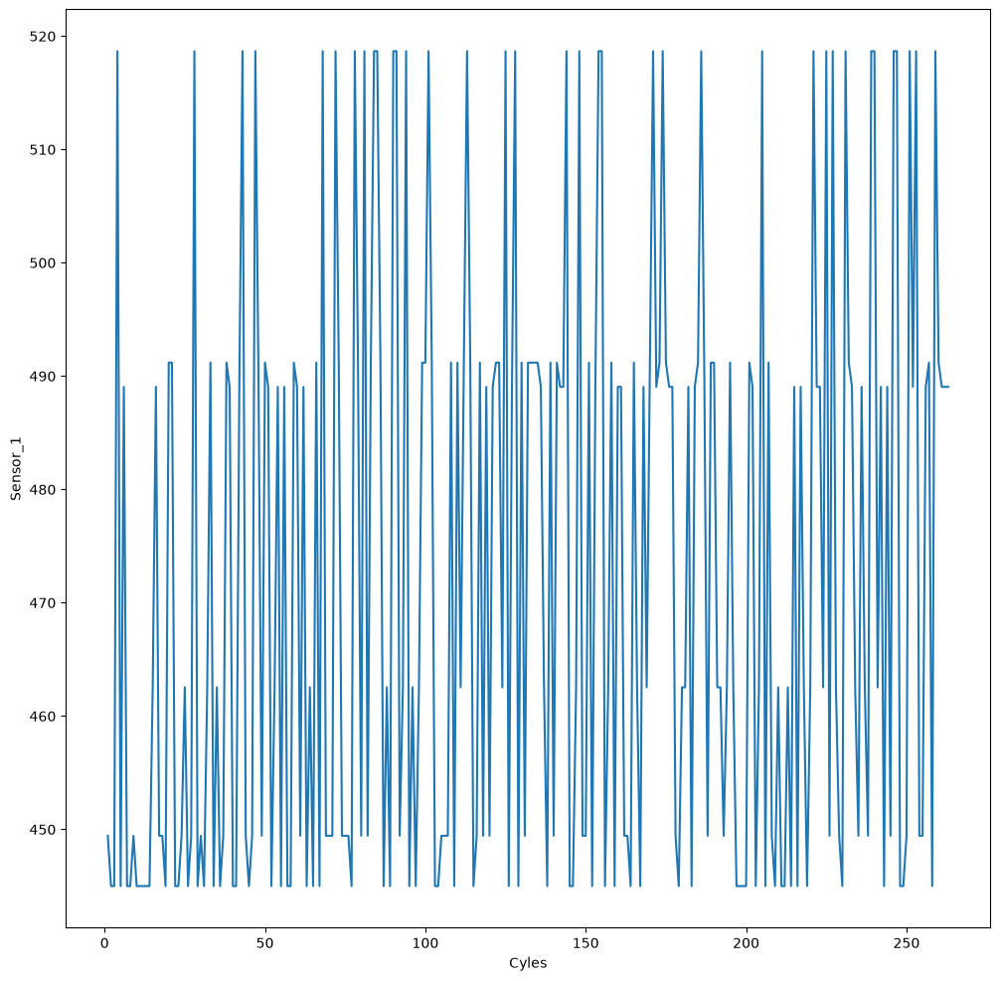

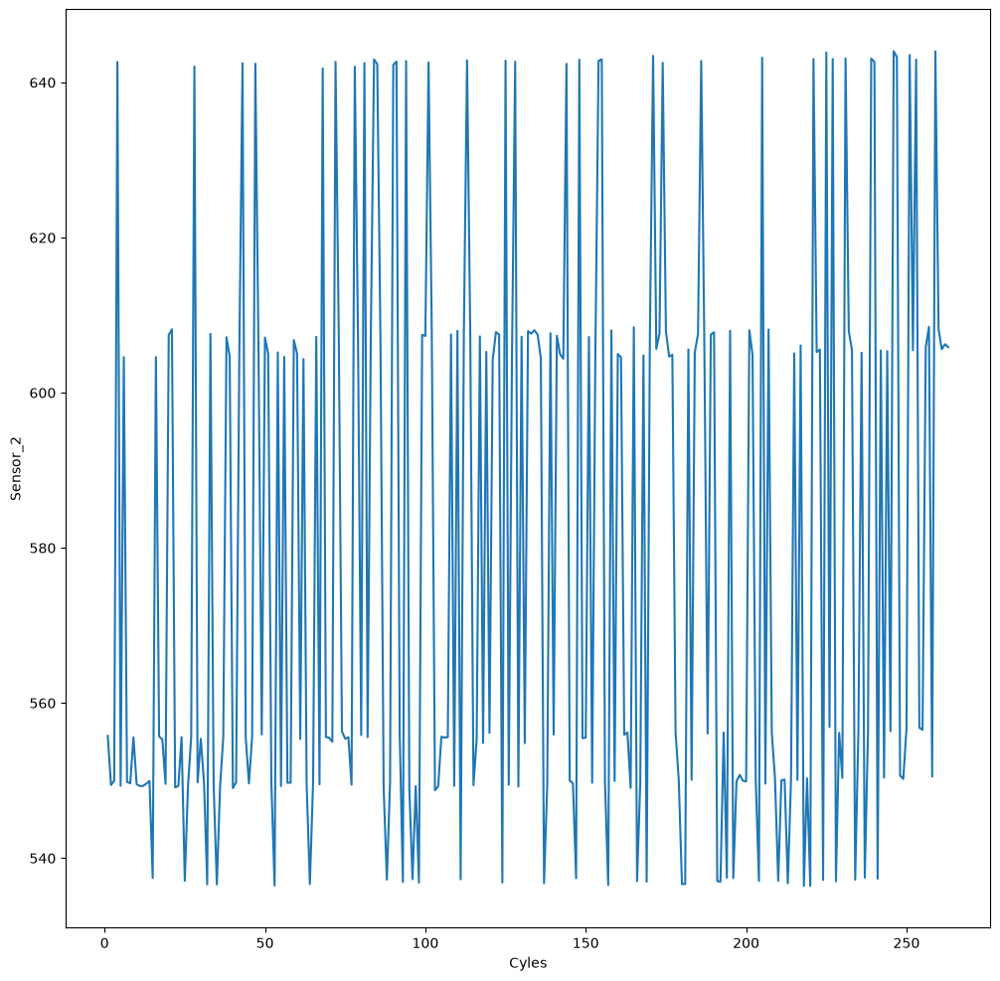

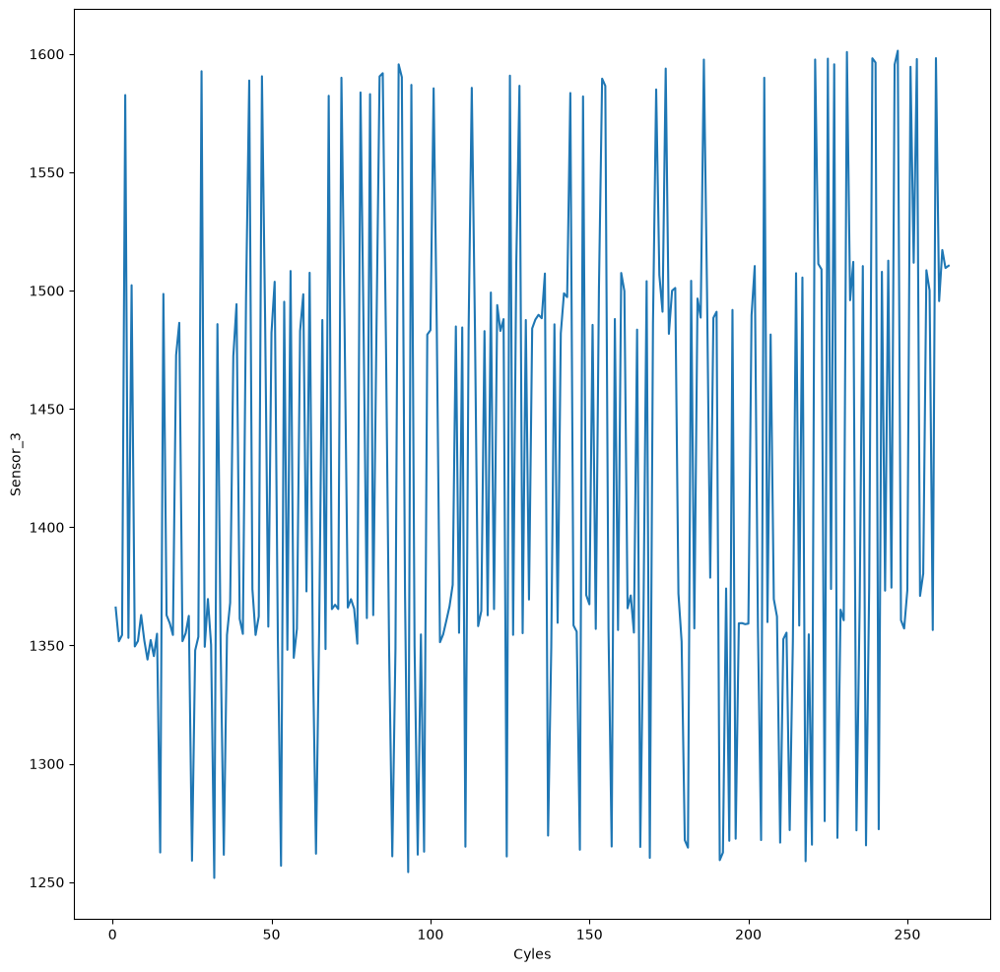

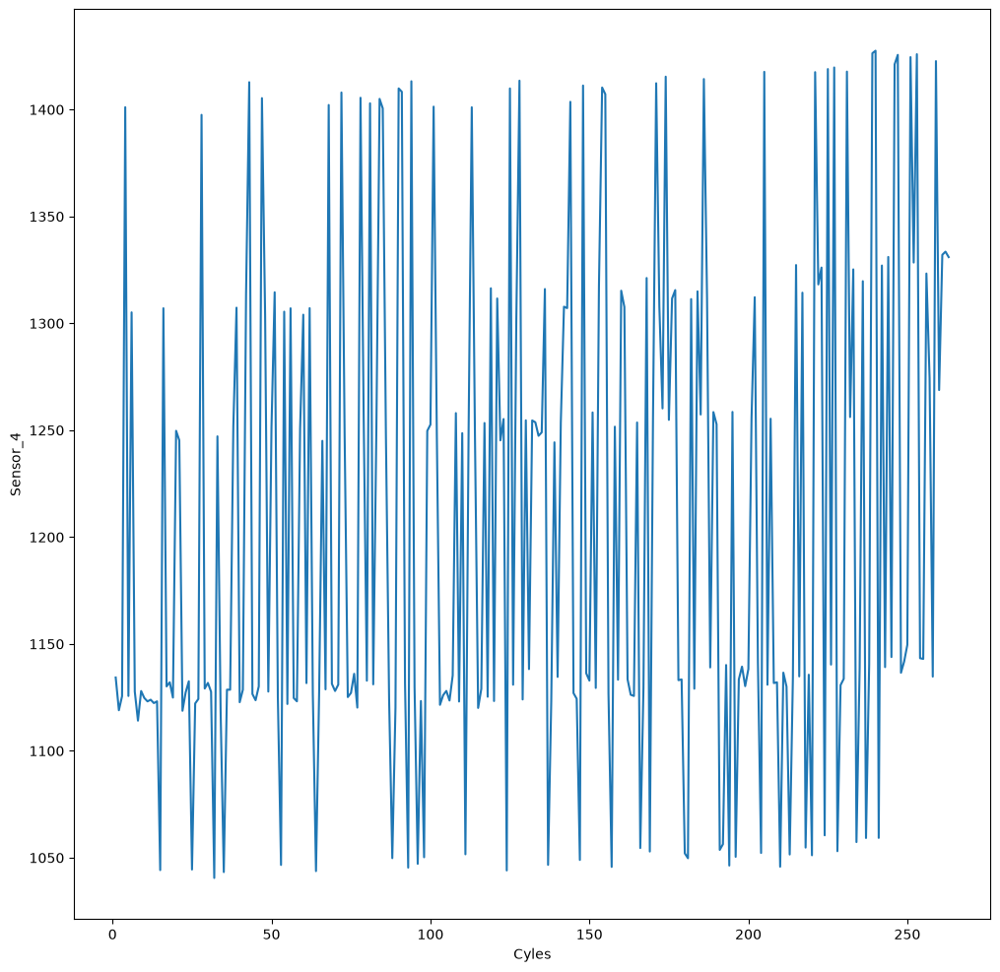

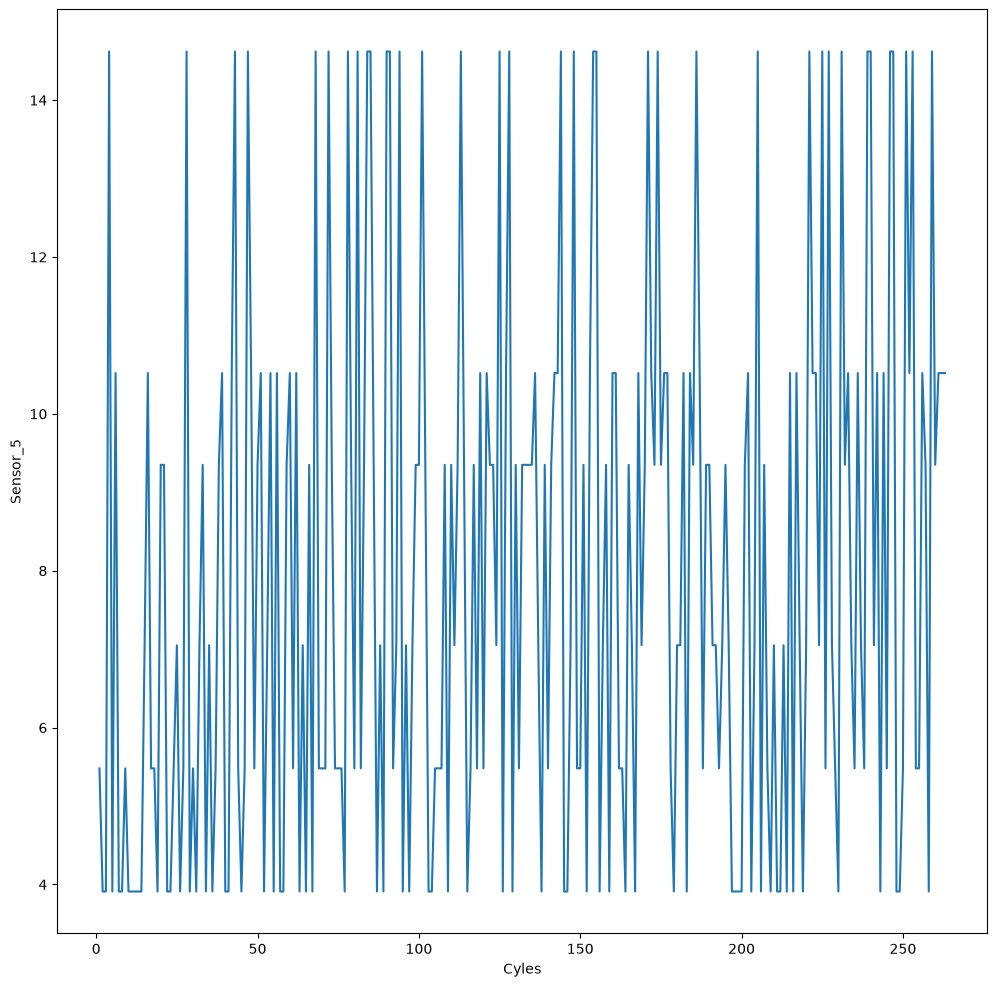

...

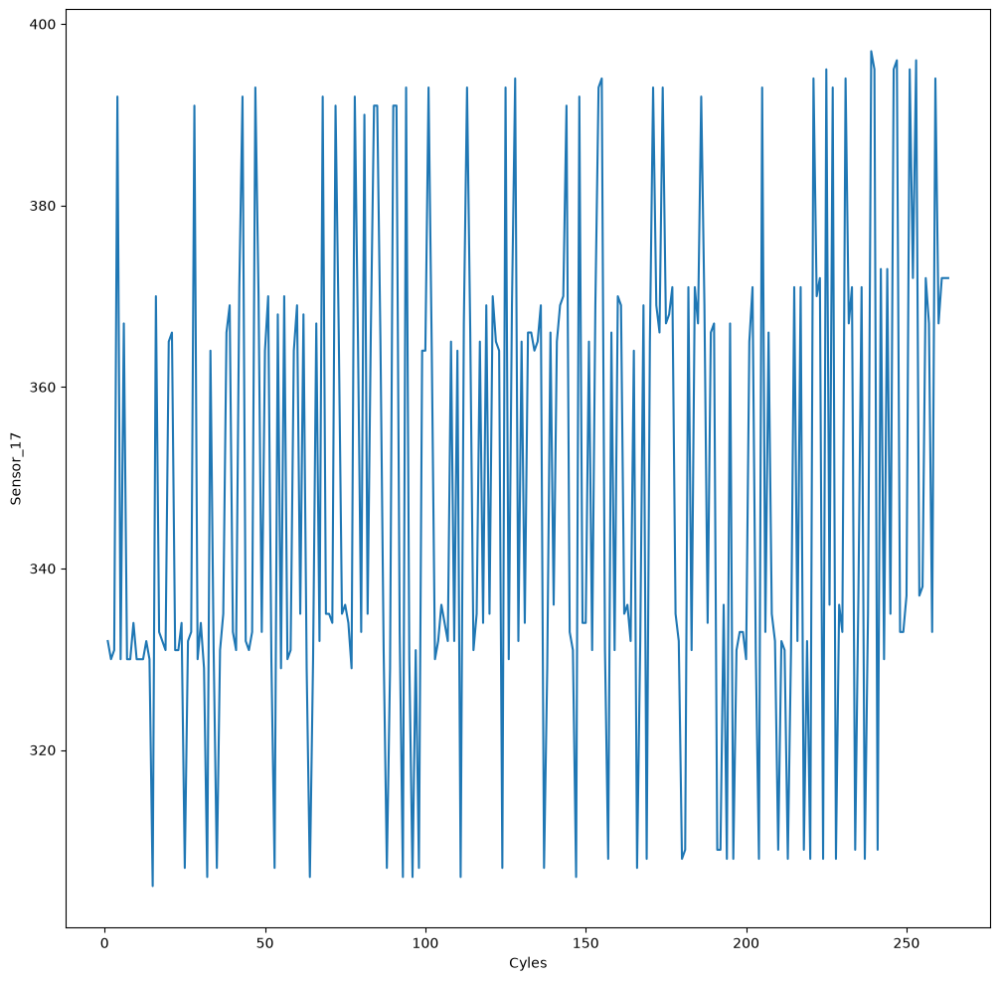

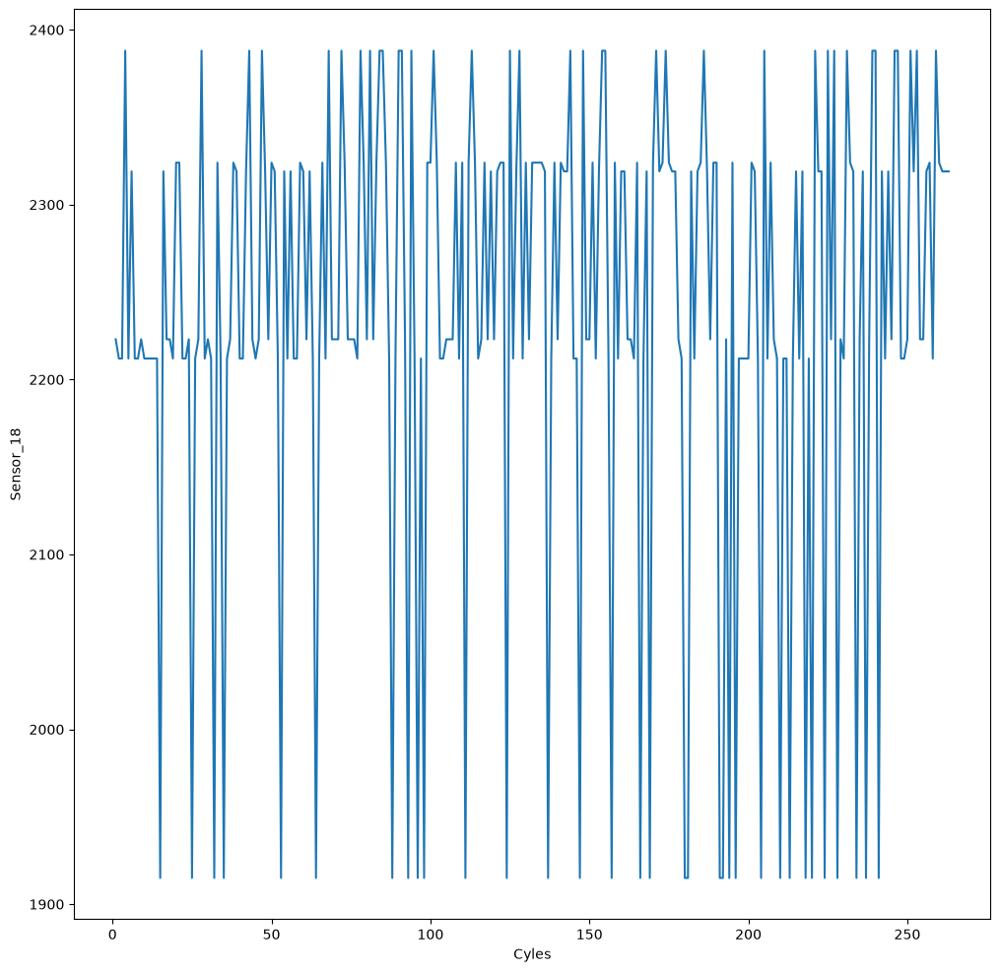

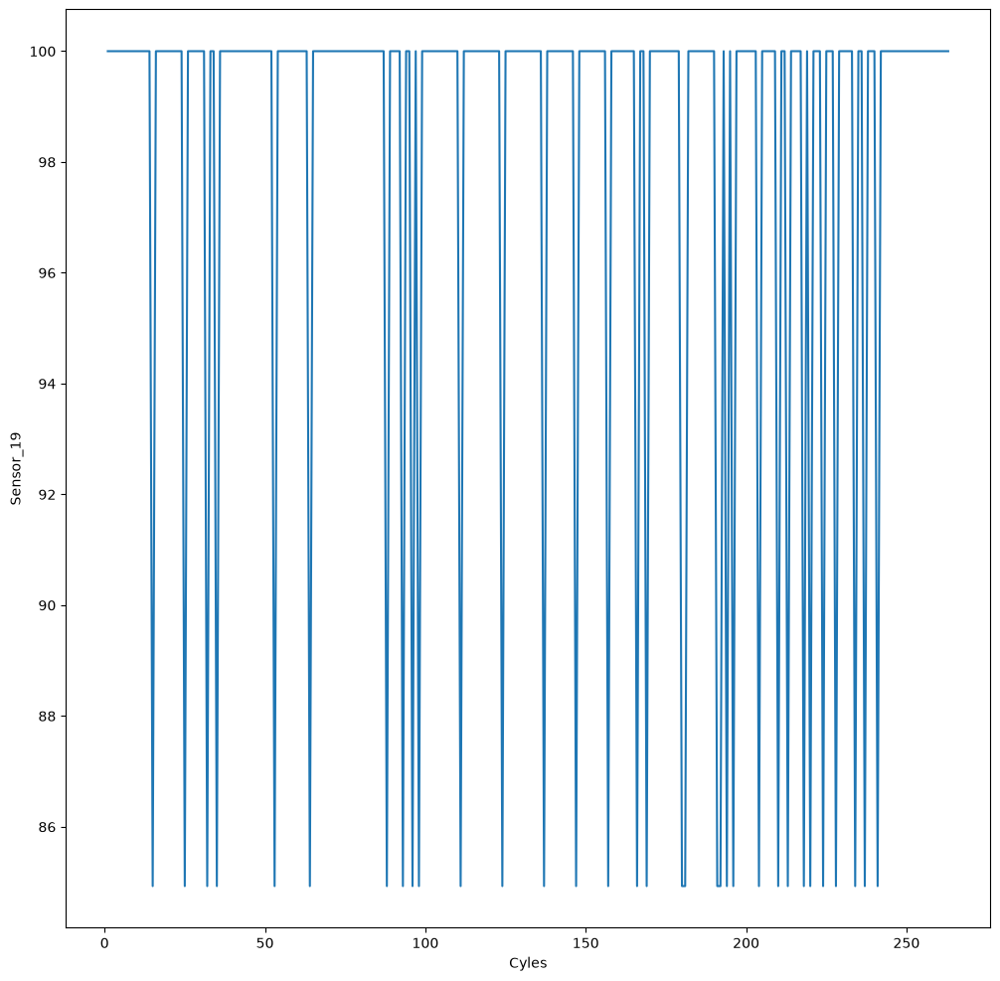

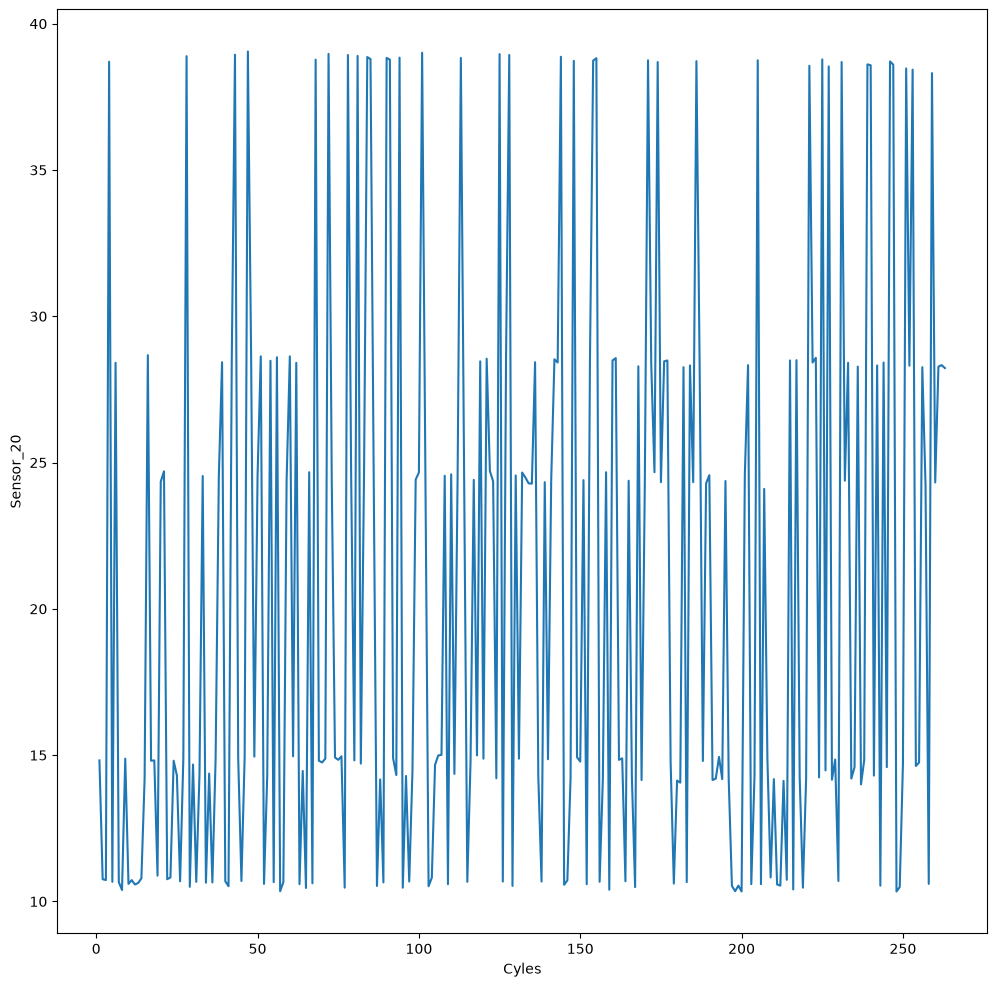

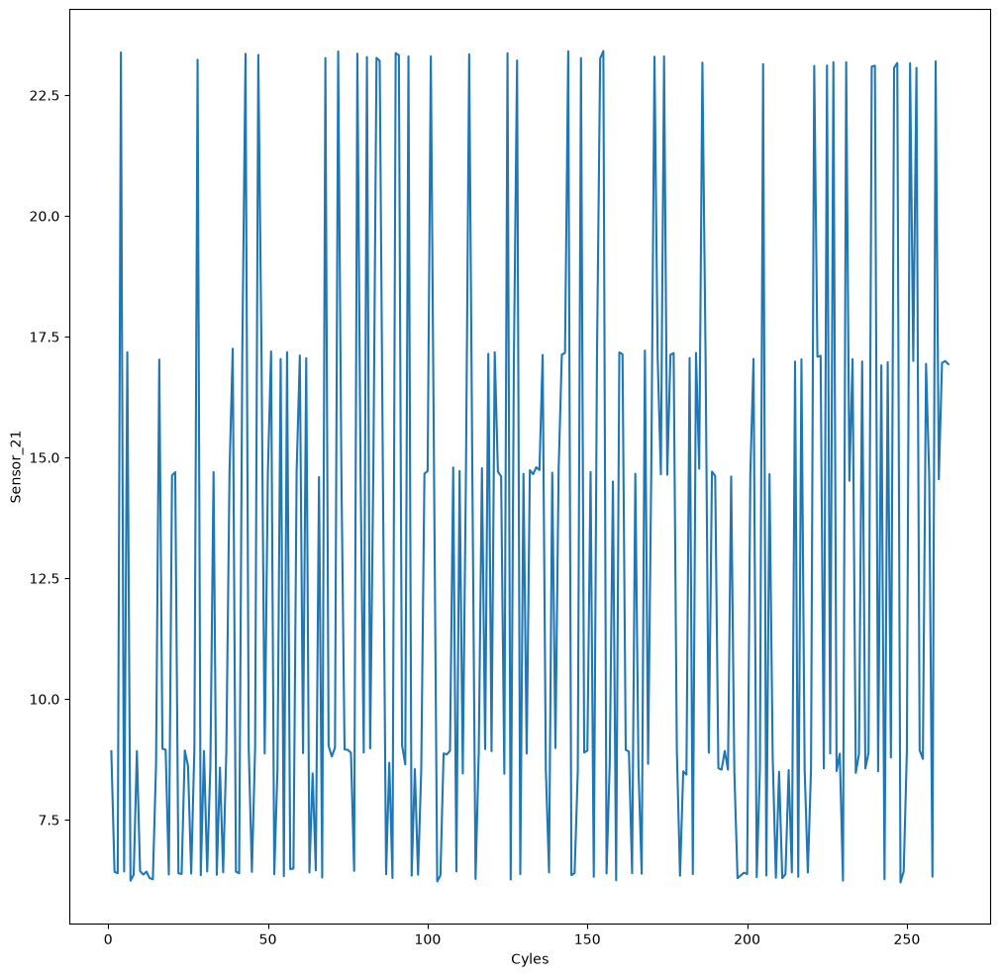

In [18]:
for i in range(1, 22):
    plt.figure(figsize = (12, 12))
    plt.plot(engine31_data['cycle'], engine31_data[f'sensor_{i}'])

    plt.xlabel("Cyles")
    plt.ylabel(f"Sensor_{i}")
    plt.show()

RANDOMLY SELECTING SOME FIVE ENGINES AND INVESTIGATING THE SENSOR READINGS AS THE CYCLE INCREASES

In [19]:
np.random.seed(42)
random_engines: np.array = np.random.randint(low = 1, high = 250, size = 5)
random_sensors: np.array = np.random.randint(low = 1, high = 22, size = 5)
random_engines, random_sensors

(array([103, 180,  93,  15, 107], dtype=int32),
 array([ 8, 21,  7, 19, 11], dtype=int32))

PLOT FOR ENGINE 103 OF CYCLE v/s SENSORS


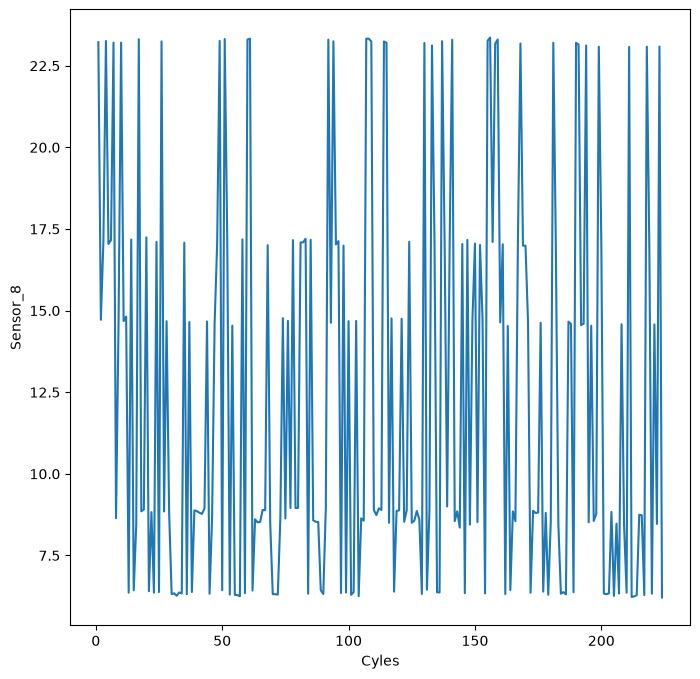

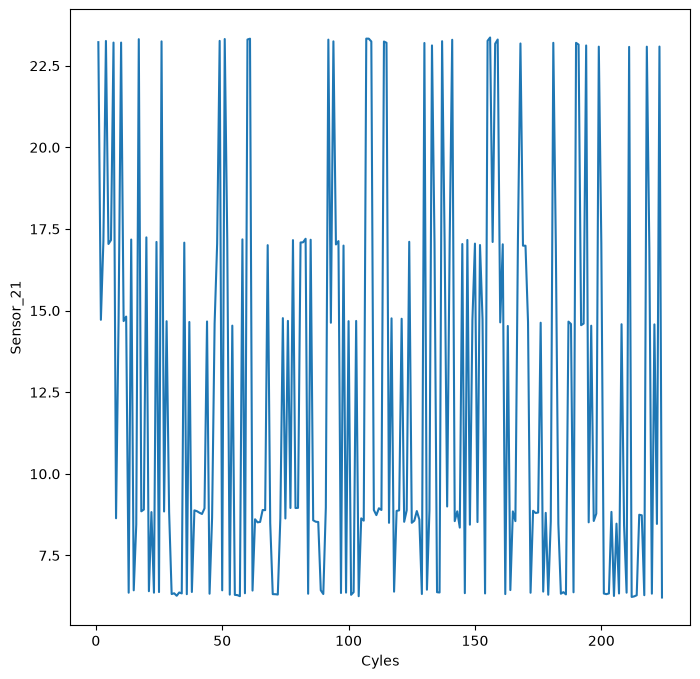

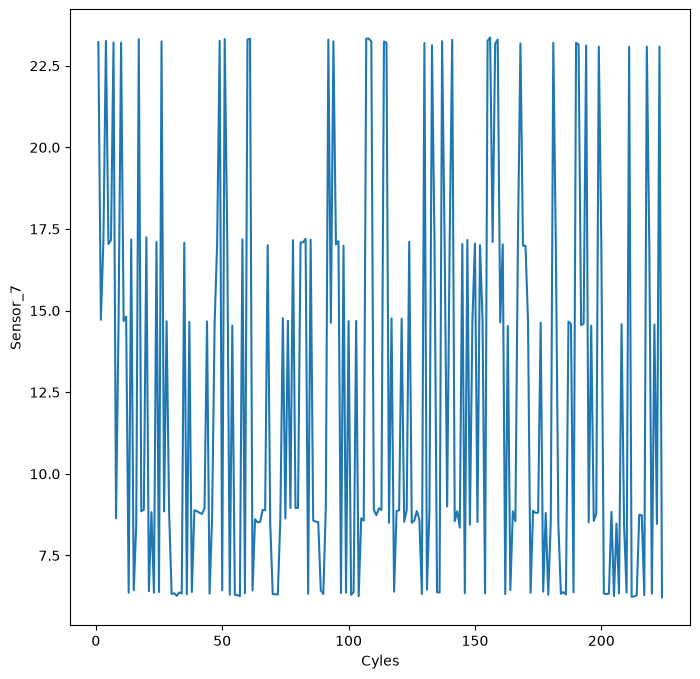

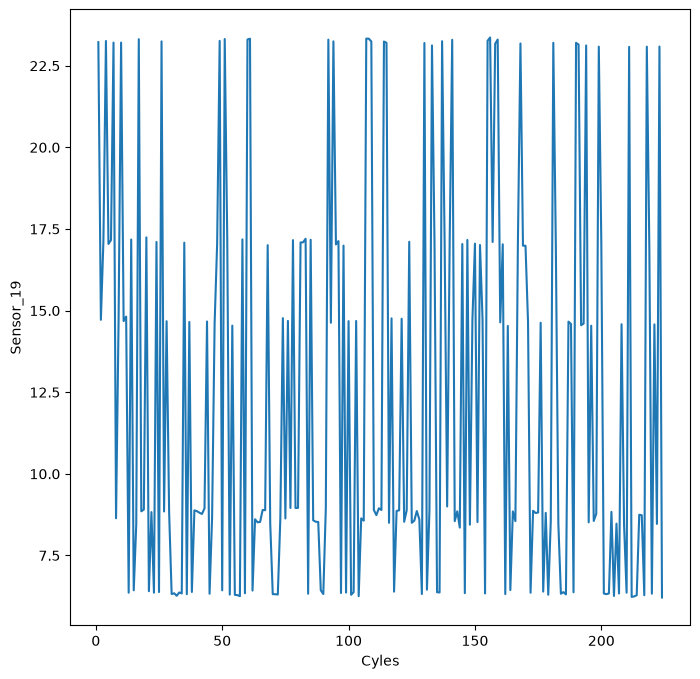

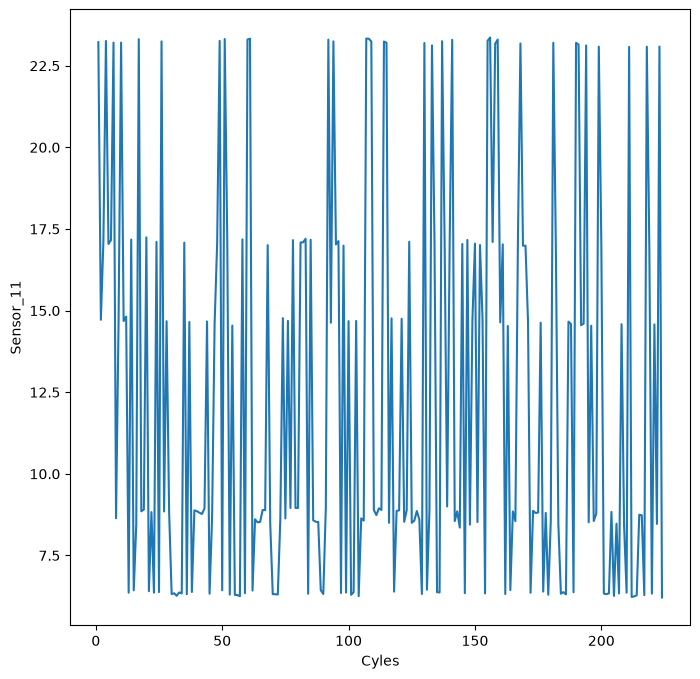

PLOT FOR ENGINE 180 OF CYCLE v/s SENSORS


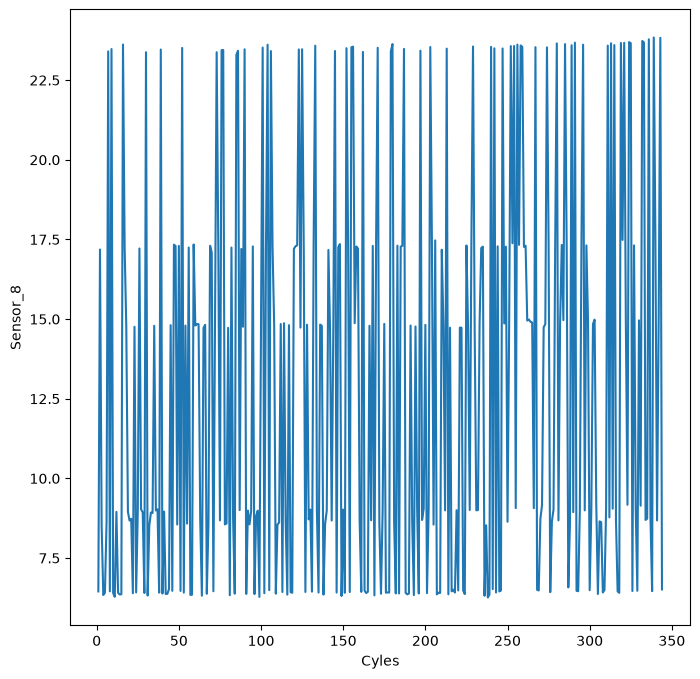

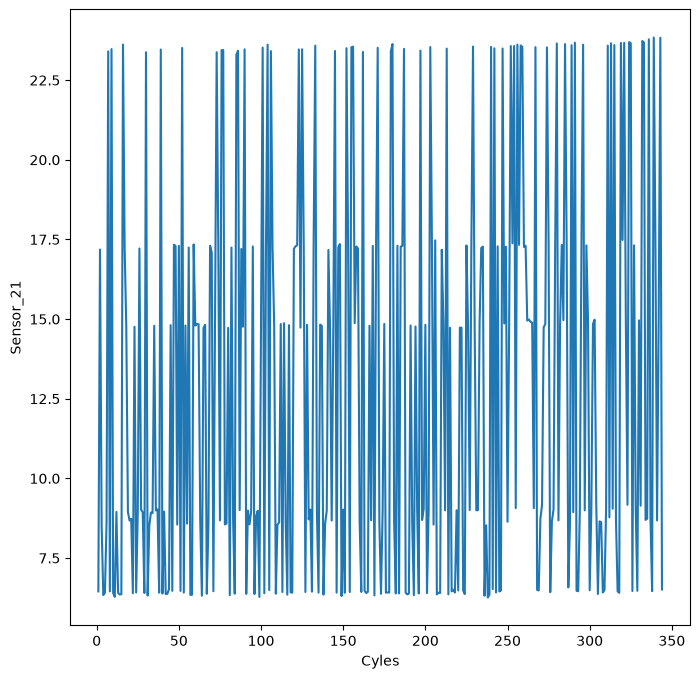

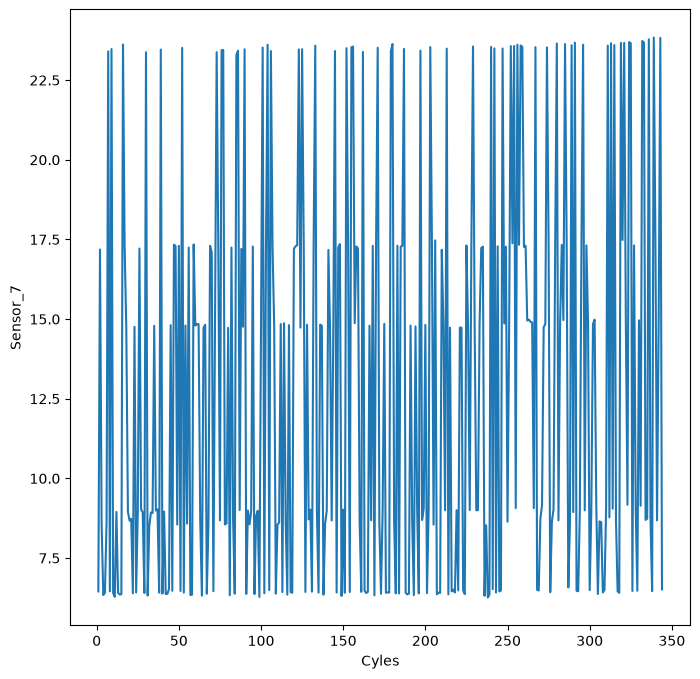

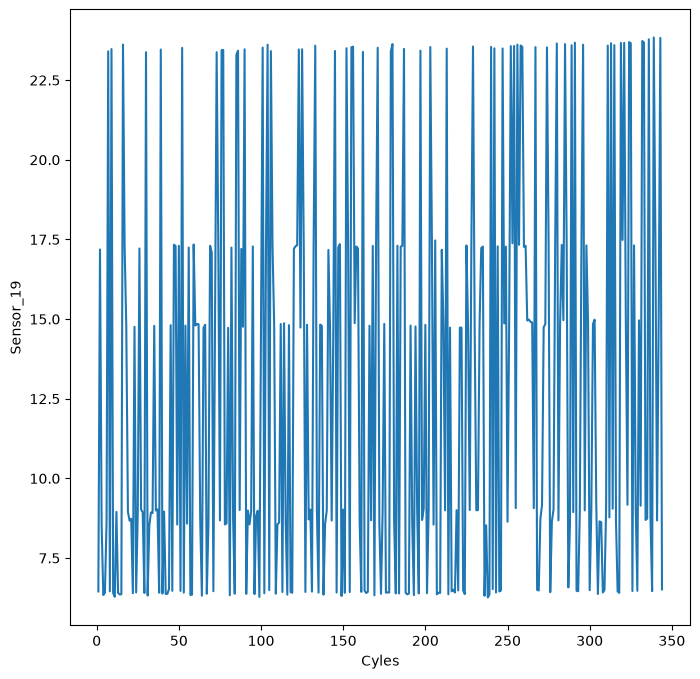

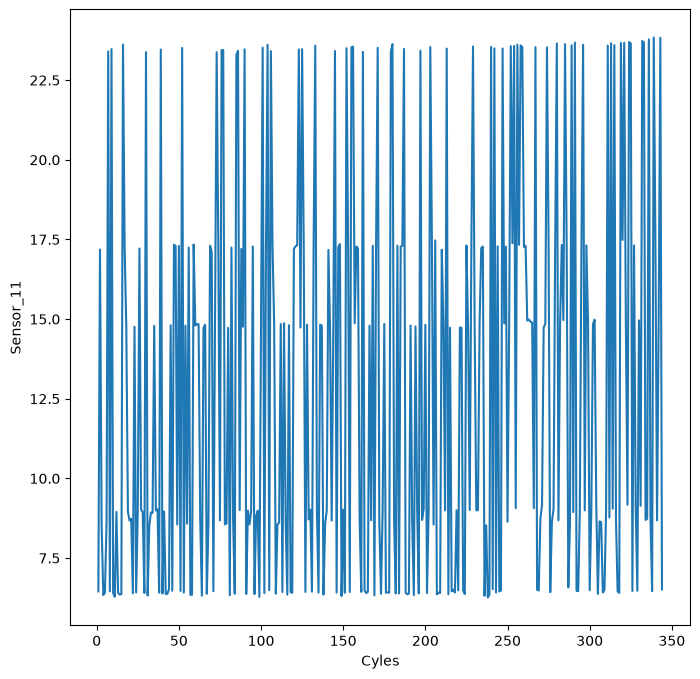

PLOT FOR ENGINE 93 OF CYCLE v/s SENSORS


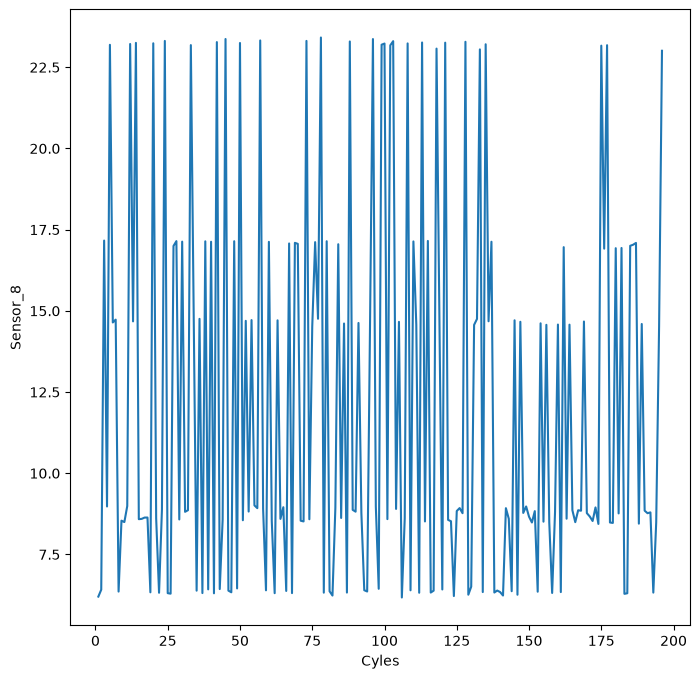

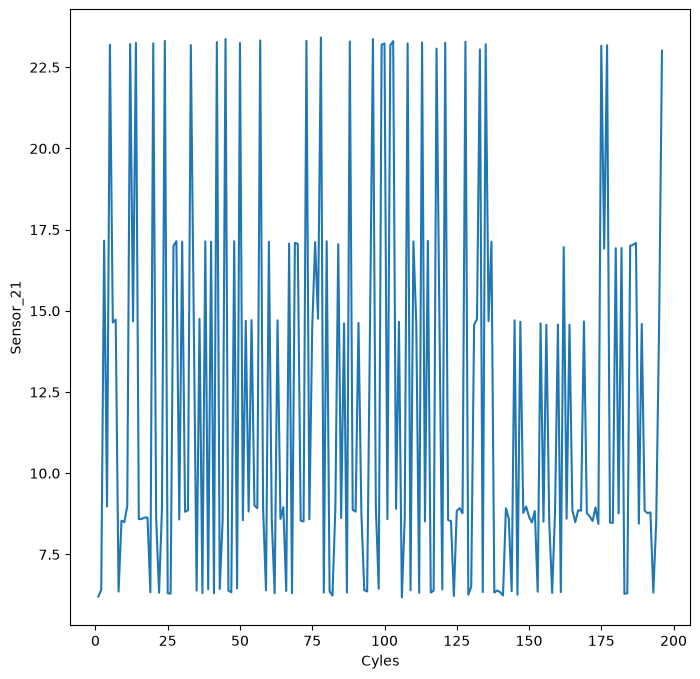

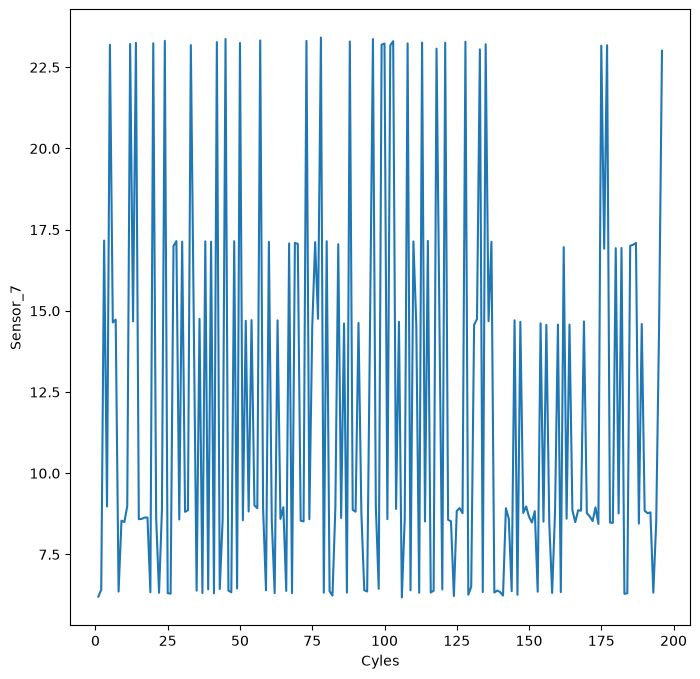

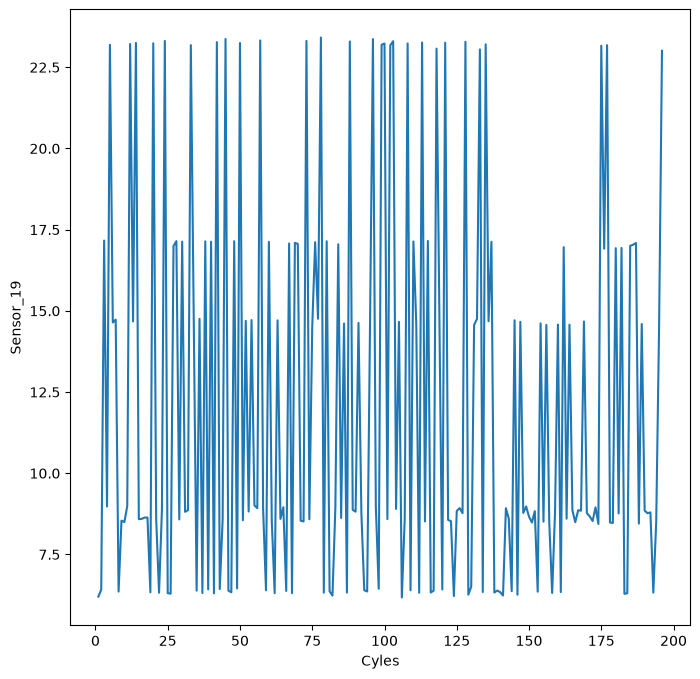

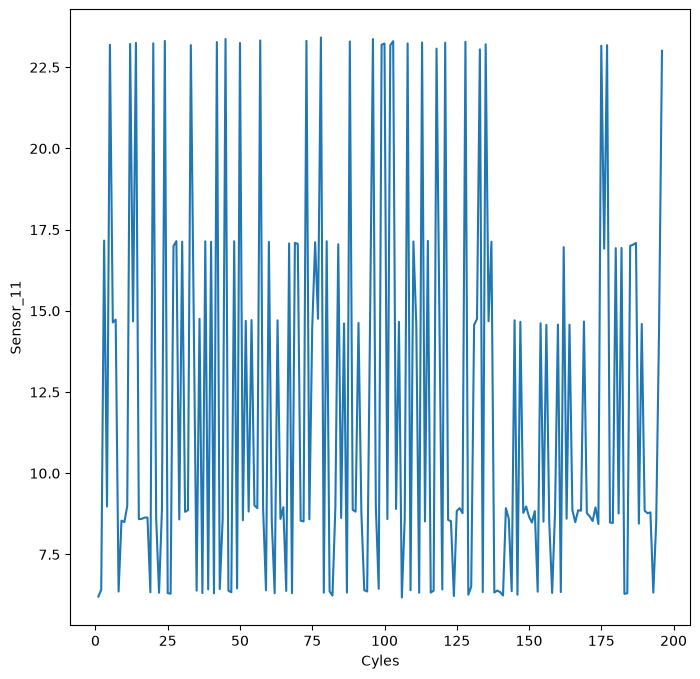

PLOT FOR ENGINE 15 OF CYCLE v/s SENSORS


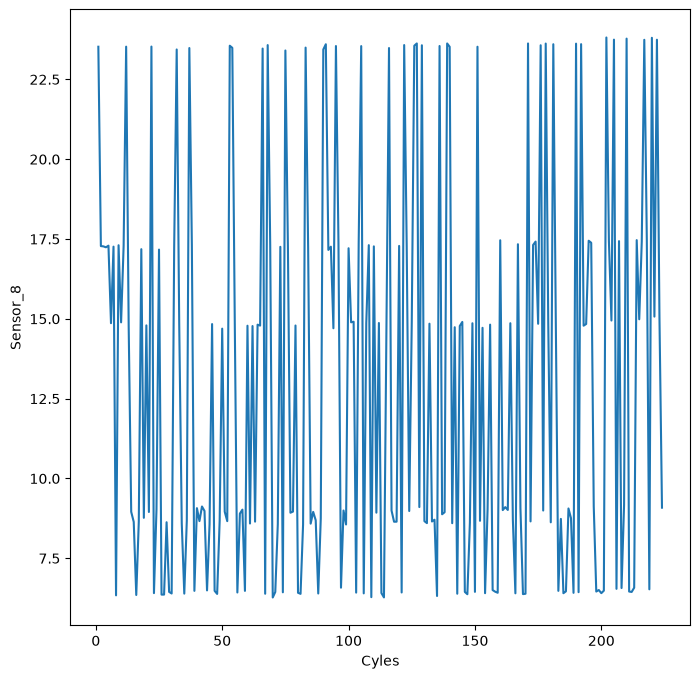

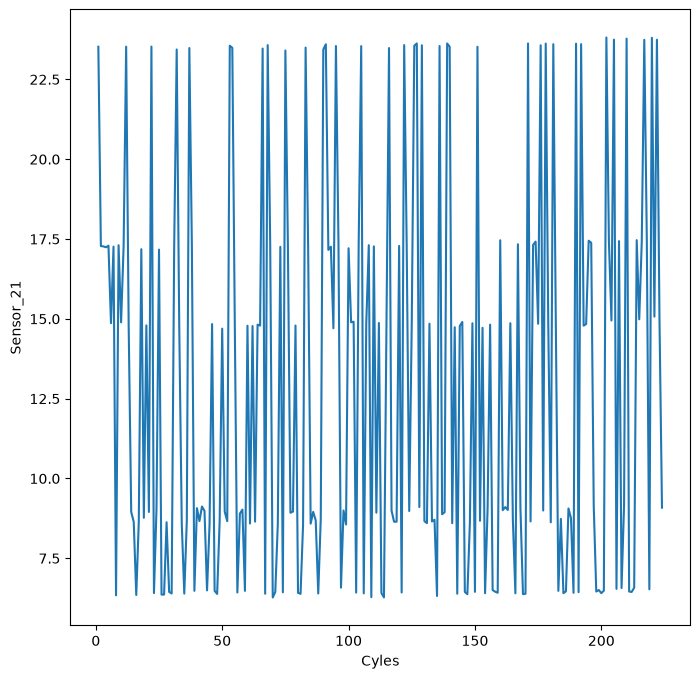

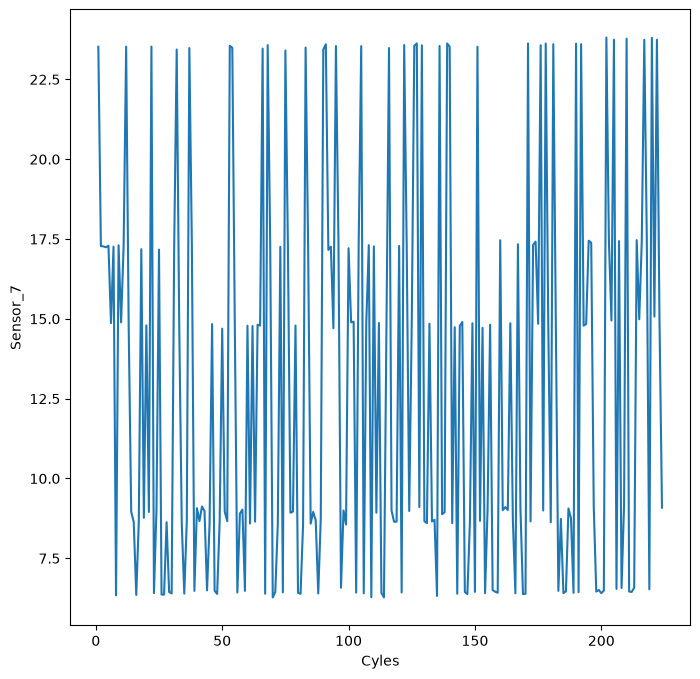

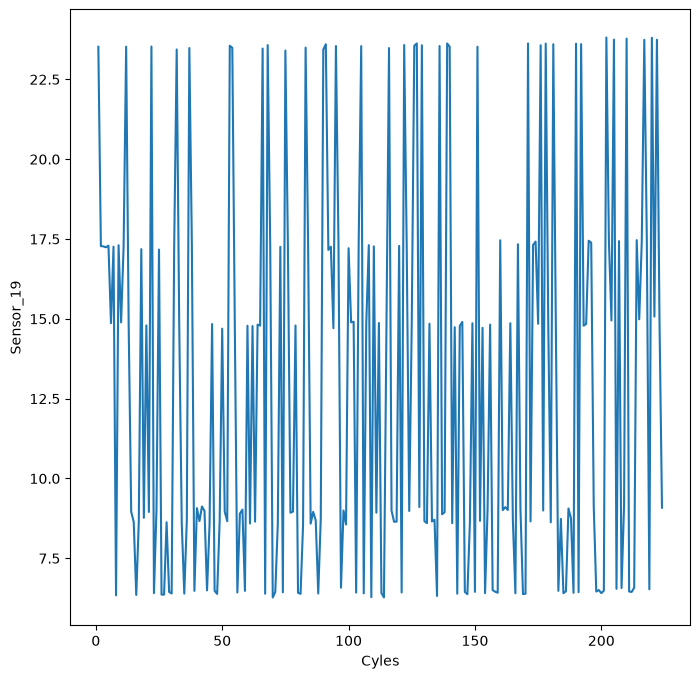

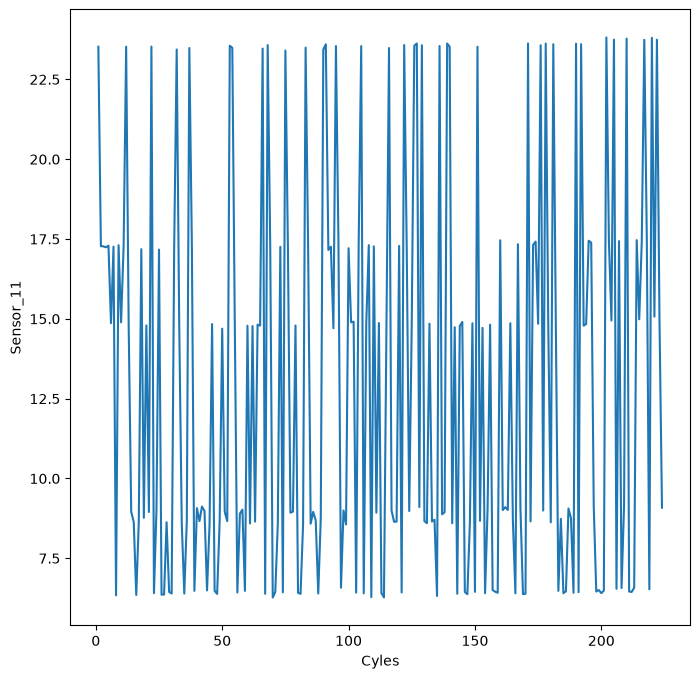

PLOT FOR ENGINE 107 OF CYCLE v/s SENSORS


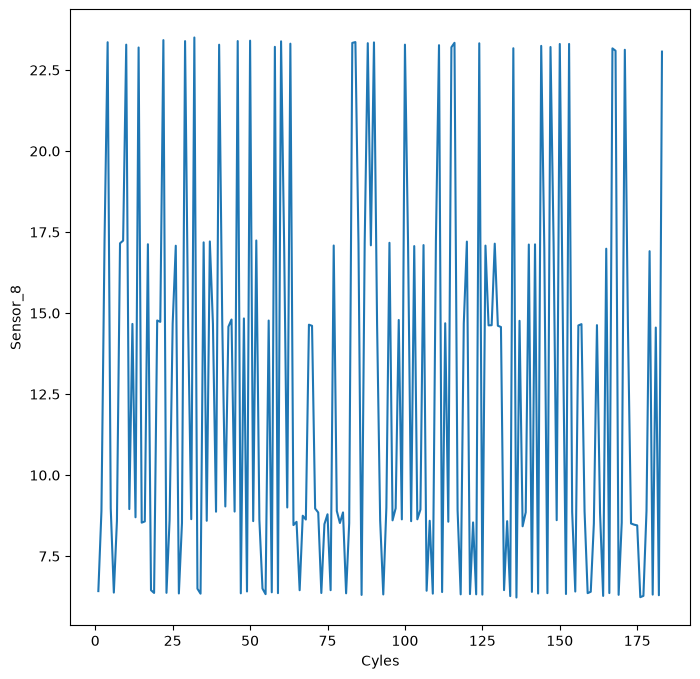

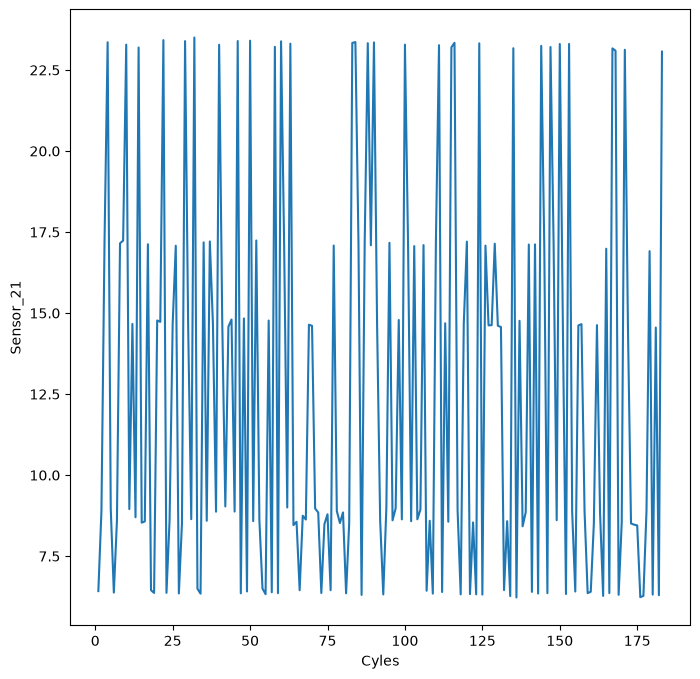

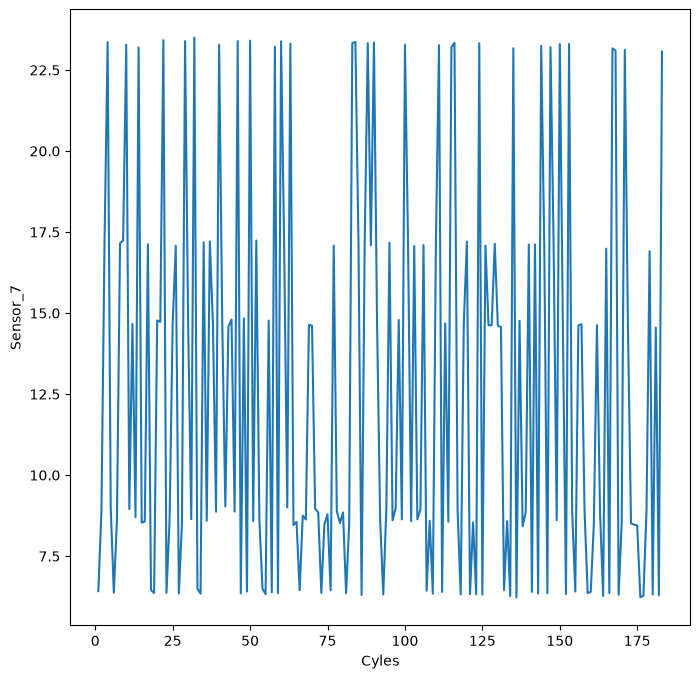

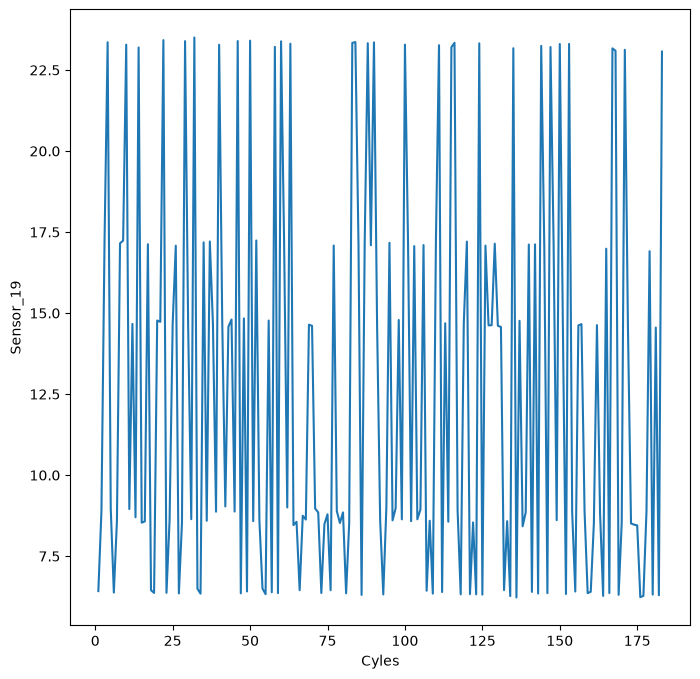

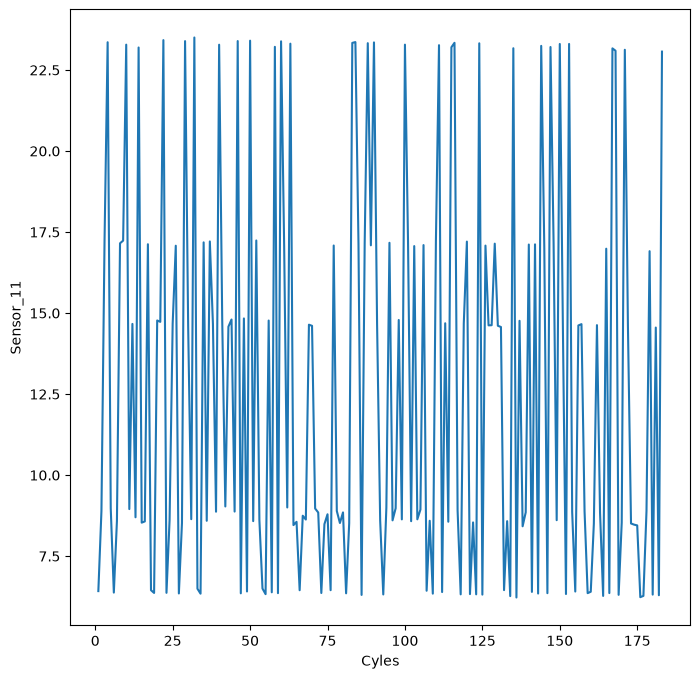

In [20]:
for engine in random_engines:
    print(f"PLOT FOR ENGINE {engine} OF CYCLE v/s SENSORS")
    for sen in random_sensors:
        plt.figure(figsize = (8, 8))
        plt.plot(
            train_data[train_data["engine_id"] == engine]['cycle'],
            train_data[train_data["engine_id"] == engine][f"sensor_{i}"]
        )

        plt.xlabel("Cyles")
        plt.ylabel(f"Sensor_{sen}")
        plt.show()


In [21]:
from src.feature_engineer import FeatureEngineerRUL
train_data, test_data, rul_data = FeatureEngineerRUL(
    train_data = train_data,
    test_data = test_data,
    rul_data = RUL_data
).engineer()

In [22]:
train_data.head()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,42.0049,0.8400,100.0,445.00,549.68,1343.43,1112.93,3.91,5.70,137.36,2211.86,8311.32,1.01,41.69,129.78,2387.99,8074.83,9.3335,0.02,330,2212,100.00,10.62,6.3670,320
1,1,2,20.0020,0.7002,100.0,491.19,606.07,1477.61,1237.50,9.35,13.61,332.10,2323.66,8713.60,1.07,43.94,312.59,2387.73,8046.13,9.1913,0.02,361,2324,100.00,24.37,14.6552,319
2,1,3,42.0038,0.8409,100.0,445.00,548.95,1343.12,1117.05,3.91,5.69,138.18,2211.92,8306.69,1.01,41.66,129.62,2387.97,8066.62,9.4007,0.02,329,2212,100.00,10.48,6.4213,318
3,1,4,42.0000,0.8400,100.0,445.00,548.70,1341.24,1118.03,3.91,5.70,137.98,2211.88,8312.35,1.02,41.68,129.80,2388.02,8076.05,9.3369,0.02,328,2212,100.00,10.54,6.4176,317
4,1,5,25.0063,0.6207,60.0,462.54,536.10,1255.23,1033.59,7.05,9.00,174.82,1915.22,7994.94,0.93,36.48,164.11,2028.08,7865.80,10.8366,0.02,305,1915,84.93,14.03,8.6754,316


In [23]:
test_data.head()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,20.0072,0.7000,100.0,491.19,606.67,1481.04,1227.81,9.35,13.60,332.52,2323.67,8704.98,1.07,43.83,313.03,2387.78,8048.98,9.2229,0.02,362,2324,100.00,24.31,14.7007,251
1,1,2,24.9984,0.6200,60.0,462.54,536.22,1256.17,1031.48,7.05,9.00,174.46,1915.21,7999.94,0.93,36.11,163.61,2028.09,7863.46,10.8632,0.02,306,1915,84.93,14.36,8.5748,250
2,1,3,42.0000,0.8420,100.0,445.00,549.23,1340.13,1105.88,3.91,5.69,137.34,2211.93,8305.38,1.01,41.52,129.98,2387.95,8071.13,9.3960,0.02,328,2212,100.00,10.39,6.4365,249
3,1,4,42.0035,0.8402,100.0,445.00,549.19,1339.70,1107.26,3.91,5.69,137.23,2211.89,8301.00,1.01,41.73,129.48,2387.90,8078.89,9.3594,0.02,328,2212,100.00,10.56,6.2367,248
4,1,5,35.0079,0.8400,100.0,449.44,555.10,1353.04,1117.80,5.48,7.97,192.94,2222.71,8331.05,1.02,41.32,181.82,2387.87,8057.83,9.3030,0.02,333,2223,100.00,14.85,8.9326,247


PLOT FOR THE LIFECYCLES OF THE ENGINES

<Axes: xlabel='cycle', ylabel='Count'>

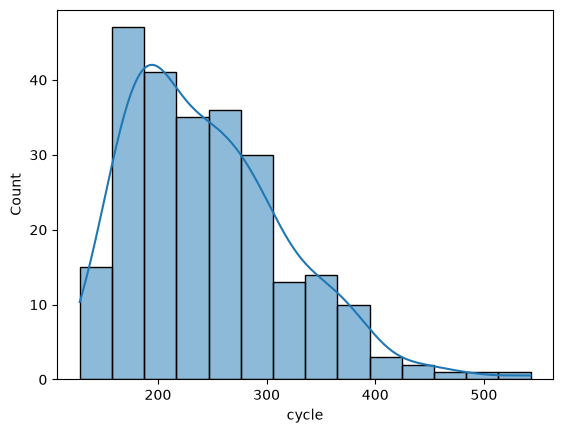

In [31]:
sns.histplot(train_data.groupby(by = "engine_id")["cycle"].max(), kde = True)

RUL DISTRIBUTION FOR THE ENGINES

<Axes: xlabel='RUL', ylabel='Count'>

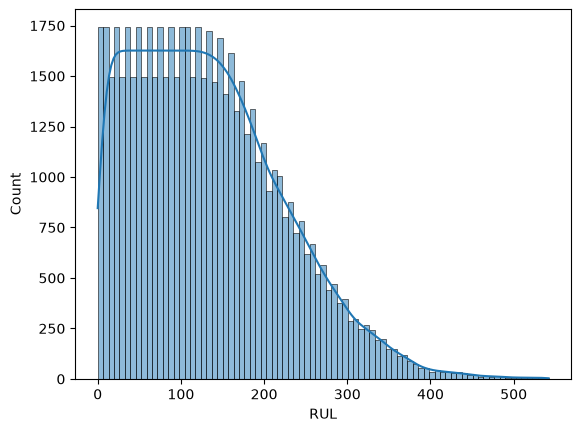

In [34]:
sns.histplot(train_data['RUL'], kde = True)

DATA PREPROCESSING PART